<a href="https://colab.research.google.com/github/CarlaDutra25/PROJETO-APLICADO-IV/blob/main/projeto_aplicado_IV_grupo_15_etapa3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  <img src="https://raw.githubusercontent.com/scalabrinig/cdProjetoAplicadoIV/d093146488f56dfcf0ef286bcee8efe0e71b9c76/figuras/mackenzie_logo.jpg" width="25%" align="right"/>

# **PROJETO APLICADO IV - Ciência de Dados EaD - 2026/02**


# **Documentação do Projeto**

---

# **PREVISÃO DE CASOS DE ARBOVIROSES E DEMANDA HOSPITALAR BASEADA EM CLIMA E SAZONALIDADE NO RIO DE JANEIRO**
---

# **Identificação do Grupo**

- Carla de Jesus Dutra Paula, 10414811

- Lucas José de Carvalho Anastacio, 10441680

# **Resumo**

Surtos de arboviroses (dengue, chikungunya e zika) pressionam a rede hospitalar do município do Rio de Janeiro de forma concentrada em poucas semanas do ano, o que dificulta o planejamento antecipado de leitos. Este projeto propõe um produto analítico que prevê a evolução semanal dos casos com até quatro semanas de antecedência e traduz essa previsão em um indicador operacional de alerta hospitalar (Normal, Atenção, Crítico). A partir de séries semanais de 2015 a 2025 do InfoDengue e de dados climáticos do Open-Meteo, foram realizadas a análise exploratória (decomposição STL, testes de estacionariedade, autocorrelação e correlação cruzada com o clima) e a comparação de técnicas de diferentes famílias: modelos autorregressivos sazonais (SARIMAX), regressão harmônica (ARIMAX com termos de Fourier), suavização exponencial (Holt-Winters), aprendizado de máquina (*Gradient Boosting*) e aprendizado profundo (LSTM), avaliadas por validação *walk-forward* em três anos (2023 a 2025) contra os baselines de persistência e ingênuo sazonal. Nos resultados preliminares, o SARIMAX sazonal com clima defasado reduziu o erro absoluto médio em cerca de 9% em relação à persistência no horizonte de quatro semanas, com intervalos de previsão de 80% bem calibrados.

# **Introdução**

A aplicação de técnicas de análise e modelagem de séries temporais na saúde pública constitui uma ferramenta estratégica na compreensão e no combate a doenças infectocontagiosas. No município do Rio de Janeiro, o caráter epidêmico recorrente de arboviroses como dengue, zika e chikungunya acarreta forte pressão sobre a rede hospitalar pública e privada: os surtos provocam picos repentinos de atendimento e internação, sobrecarregando a infraestrutura de saúde e dificultando o planejamento antecipado de leitos, escalas médicas e aquisição de insumos críticos.

A proliferação do vetor *Aedes aegypti* e a dinâmica de contágio no território fluminense mantêm relação direta com variáveis meteorológicas (temperatura e precipitação acumulada) e com padrões sazonais específicos da região. A construção de modelos preditivos que relacionem condicionantes climáticos defasados à evolução de casos e internações viabiliza a transição de uma gestão hospitalar reativa para uma atuação preventiva e otimizada, que seria a motivação central deste projeto.

**Objetivo geral:** desenvolver e validar um produto analítico preditivo em duas camadas:

1. Modelagem temporal multivariada para estimar a incidência de casos e internações por arboviroses no Rio de Janeiro com base em fatores climáticos e sazonalidade
2. Um modelo de classificação operacional que categoriza o nível de alerta de demanda hospitalar (Normal, Atenção, Crítico), cruzando as previsões temporais com a capacidade instalada de leitos do Sistema Único de Saúde (SUS).

**Objetivos específicos:**

1. Consolidar e harmonizar os registros históricos epidemiológicos e meteorológicos do Rio de Janeiro na escala de Semana Epidemiológica (2015–2025)
2. Caracterizar os componentes estruturais das séries temporais (tendência, sazonalidade, ciclos e autocorrelação)
3. Implementar e comparar técnicas preditivas de diferentes famílias: estatísticas (SARIMAX e ARIMAX com termos de Fourier), de suavização exponencial (Holt-Winters), de aprendizado de máquina (*Gradient Boosting*) e de aprendizado profundo (LSTM)
4. Construir e calibrar o modelo de classificação de risco hospitalar com o suporte técnico de especialistas da Secretaria Municipal de Saúde do Rio de Janeiro (SMS-Rio)
5. Disponibilizar os resultados em uma interface de documentação analítica interativa no GitHub

**Base de dados:** composta por séries temporais multivariadas organizadas segundo o calendário oficial de Semanas Epidemiológicas, cobrindo o período contínuo de 2015 a 2025 no Rio de Janeiro. As fontes utilizadas são:

- **InfoDengue (Fiocruz/FGV):** histórico semanal de notificações estimadas e confirmadas de dengue, zika e chikungunya, taxa de incidência e níveis regionais de alerta
- **Departamento de Informática do SUS (DATASUS), com o Sistema de Informação de Agravos de Notificação (SINAN) e o Sistema de Informações Hospitalares (SIH-SUS):** notificações de agravos e Autorizações de Internação Hospitalar (AIH) decorrentes de arboviroses na rede pública
- **Open-Meteo (reanálise meteorológica):** temperatura média, temperatura máxima e precipitação pluviométrica acumulada semanais
- **Cadastro Nacional de Estabelecimentos de Saúde (CNES):** capacidade instalada de leitos de enfermaria e UTI, utilizada como referência para a classificação de níveis de alerta hospitalar

**Justificativa:** embora existam plataformas consolidadas de monitoramento epidemiológico no Brasil - como o próprio InfoDengue - este projeto se diferencia em três pontos:

1. **Foco na demanda hospitalar operacional**, e não apenas no risco de notificação/transmissão populacional, ao modelar a conversão de contágios em internações e necessidade real de leitos
2. **Arquitetura em duas camadas**, integrando a previsão quantitativa de séries temporais (SARIMAX, LSTM e outras técnicas comparadas) a uma camada de classificação funcional de alerta hospitalar
3. **Validação prática com especialistas da rede da SMS-Rio**, com ciclos formais de calibração técnica ao longo do desenvolvimento.

O projeto alinha-se às diretrizes da Agenda 2030 da Organização das Nações Unidas (ONU), por meio dos Objetivos de Desenvolvimento Sustentável (ODS), contemplando diretamente:

- **ODS 3 - Saúde e Bem Estar:** Ao fornecer instrumentos de inteligência preditiva para apoiar a gestão hospitalar e a resposta rápida a epidemias.
- **ODS 11 - Cidades e Comunidades Sustentáveis:** Ao fortalecer a resiliência dos sistemas urbanos de saúde frente a variabilidades climáticas e surtos sazonais em grandes metrópoles.

# **Referencial Teórico**

A modelagem preditiva de doenças de transmissão vetorial a partir de séries temporais é um campo consolidado, com abordagens que evoluíram de modelos estatísticos clássicos para técnicas híbridas que combinam estatística e aprendizado profundo.

**1. Modelos estatísticos clássicos (SARIMA/SARIMAX)**

- O modelo **SARIMA/SARIMAX** (*Seasonal Autoregressive Integrated Moving Average with eXogenous variables*), fundamentado em Box e Jenkins (1970), continua sendo referência para previsão epidemiológica.
- Martinez e Silva (2011), em estudo com dados de dengue em Ribeirão Preto (SP), validaram sua aplicabilidade a séries de casos com forte componente sazonal.
- **Vantagem:** interpretabilidade dos coeficientes e baixo custo computacional.
- **Limitação:** suposição de relações predominantemente lineares entre a série e as variáveis exógenas, o que pode não capturar toda a complexidade de fenômenos climático-epidemiológicos.

**2. Modelos de aprendizado profundo (LSTM)**

- Redes **LSTM** (*Long Short-Term Memory*), propostas por Hochreiter e Schmidhuber (1997), vêm sendo aplicadas ao mesmo problema por sua capacidade de capturar dependências não lineares e de longo prazo.
- Sahd et al. (2026) compararam diretamente SARIMAX e LSTM para previsão de dengue em Londrina (PR), incorporando temperatura e umidade como variáveis exógenas.
- **Resultado:** o SARIMAX apresentou desempenho mais estável, enquanto a LSTM, apesar de maior volatilidade nas previsões, mostrou-se promissora, o que motiva a comparação entre as duas técnicas também neste projeto, em vez de se adotar uma única abordagem a priori.

**3. Trabalhos aplicados ao Rio de Janeiro e à demanda hospitalar**

- A literatura recente já avaliou modelos estatísticos e de aprendizado de máquina para previsão de dengue especificamente no Rio de Janeiro, reforçando a viabilidade metodológica do recorte geográfico escolhido.
- Também há trabalhos que investigam especificamente a previsão de **internações** por dengue no Brasil a partir de dados climáticos, considerando os atrasos reais de notificação (*reporting delays*) — desafio prático também enfrentado neste projeto, dado o uso de dados de AIH/SIH-SUS.
- *(As referências completas desses dois trabalhos estão em processo de validação de autoria e serão incorporadas na próxima atualização da bibliografia.)*

**4. Técnicas de decomposição e transformação**

- A **decomposição STL** (*Seasonal-Trend decomposition using Loess*), proposta por Cleveland et al. (1990), foi adotada para caracterizar a série por ser mais robusta a sazonalidade de amplitude variável o que é relevante neste caso, já que surtos de arbovirose não apresentam a mesma intensidade sazonal ano a ano.
- A estabilização de variância da série de casos foi realizada pela **transformação de Box-Cox** (Box e Cox, 1964), com o parâmetro ótimo estimado pelo método de Guerrero (1993).

**5. Diferencial do projeto**

A maior parte da literatura correlata concentra-se em prever **incidência de casos**, não a **demanda operacional de leitos**. Este projeto se diferencia ao:

- Integrar a previsão de séries temporais (SARIMAX/LSTM) a uma camada de classificação de risco hospitalar
- Calibrar essa classificação com a capacidade instalada de leitos (CNES)
- Validar o resultado com profissionais da SMS-Rio, traduzindo a previsão epidemiológica em uma decisão operacional direta para a gestão hospitalar

# **Diagrama de Solução**

A Figura 1 apresenta o pipeline da solução, revisado nesta etapa. Em relação à versão da Etapa 2, foram incorporadas três mudanças: (i) a variável-alvo passou a ser a soma de dengue e chikungunya, porque a fonte deixou de publicar dados de zika para o município após fevereiro de 2024; (ii) a etapa de modelagem passou a comparar cinco técnicas de famílias diferentes, e não apenas SARIMAX e LSTM; e (iii) a camada operacional ganhou a desagregação da previsão por Área de Planejamento (AP), unidade territorial usada pela SMS-Rio.

![Diagrama de Solução](diagrama_solucao_etapa3.png)

**Figura 1 — Pipeline da solução proposta (versão revisada na Etapa 3).**

1. **Coleta de dados:** casos semanais estimados de dengue, chikungunya e zika do InfoDengue (CODEÇO et al., 2018) e dados diários de temperatura e precipitação do Open-Meteo (ZIPPENFENIG, 2023), de 2015 a 2025. Para a camada operacional (Etapa 4), internações do SIH-SUS, leitos do CNES e casos notificados por AP do Tabnet Municipal da SMS-Rio.
2. **Pré-processamento:** agregação do clima por semana epidemiológica (domingo a sábado), interpolação de lacunas internas, construção da variável-alvo e transformação logarítmica.
3. **Análise exploratória:** decomposição STL, testes de estacionariedade (ADF e KPSS), autocorrelação (ACF/PACF), sazonalidade, picos por doença e correlação cruzada entre clima e casos.
4. **Modelagem e validação:** baselines (persistência e ingênuo sazonal) e cinco técnicas candidatas, avaliadas por validação *walk-forward* em 2023, 2024 e 2025, com previsões de 1 a 4 semanas à frente e intervalos de previsão de 80%.
5. **Camada operacional (Etapa 4):** conversão de casos previstos em leitos ocupados, alerta Normal/Atenção/Crítico, desagregação por AP e validação com a equipe técnica da SMS-Rio.

# **Cronograma**

A Tabela 1 apresenta o cronograma atualizado. As atividades concluídas foram resumidas, e as atividades restantes até a entrega final foram detalhadas e associadas aos objetivos específicos (OE) definidos na Introdução.

**Tabela 1 — Cronograma atualizado do projeto**

| Período | Atividade | OE | Status |
|---|---|---|---|
| até 31/08 | Entrega 1: definição do grupo, tema, objetivos e bases de dados | — | Concluído |
| 01/09 – 28/09 | Referencial teórico, coleta inicial (InfoDengue e Open-Meteo), primeira análise exploratória e Entrega 2 | OE1, OE2 | Concluído |
| 29/09 – 15/10 | Modelos iniciais (baselines, ARIMAX com Fourier, SARIMAX) e validação *walk-forward* 2023–2025 | OE3 | Concluído |
| 13/10 – 15/10 | Coleta de SIH-SUS, CNES e Tabnet por AP; primeiro protótipo da camada hospitalar | OE4 | Concluído (preliminar) |
| 16/10 – 25/10 | Análise exploratória consolidada, comparação de técnicas (Holt-Winters, *Gradient Boosting*, LSTM) e revisão do pipeline | OE2, OE3 | Concluído |
| **26/10** | **Entrega 3: análise exploratória, modelo base, cronograma e pipeline atualizados** | — | Em entrega |
| 27/10 – 02/11 | Refinamento dos modelos: ajuste de hiperparâmetros da LSTM e do *Gradient Boosting*, análise de resíduos e comparação estatística entre modelos | OE3 | Planejado |
| 03/11 – 09/11 | Camada hospitalar: limiares de alerta baseados em leitos do CNES; previsão por AP com histórico 2015–2022 e chikungunya | OE4 | Planejado |
| 10/11 | Checkpoint da Etapa 4 (encontro às 19h) | — | Planejado |
| 10/11 – 20/11 | Reunião com a equipe técnica da SMS-Rio (data a confirmar) e calibração dos limiares de alerta | OE4 | Planejado |
| 21/11 – 27/11 | Análise crítica final, escolha do modelo, documentação, README e gravação do vídeo | OE3, OE5 | Planejado |
| **30/11** | **Entrega 4: implementação final, GitHub, vídeo e notebook do projeto** | OE5 | Planejado |

# **EDA e Pré-processamento dos dados**

Tendo em vista os objetivos específicos OE1 e OE2, esta seção consolida as bases de dados, descreve as decisões de preparação e caracteriza a série temporal antes da modelagem. A ordem segue o roteiro de modelagem de séries temporais apresentado na disciplina: coleta e verificação de qualidade, preparação, visualização e caracterização analítica (tendência, sazonalidade, estacionariedade e autocorrelação) e, por fim, a relação com as variáveis exógenas. Cada análise termina com a decisão de modelagem que ela motiva, resumida na Tabela 7.

> **Reprodutibilidade:** o notebook consulta as APIs públicas do InfoDengue e do Open-Meteo e salva uma cópia dos dados brutos na pasta `dados/`. Se alguma API estiver indisponível, a cópia salva é usada. Nenhum dado sintético é utilizado.

## **1. Configuração**

In [2]:
pip install sklearn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [5]:
pip install --upgrade pip

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 1.8/1.8 MB 10.7 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.2.1
    Uninstalling pip-26.2.1:
      Successfully uninstalled pip-26.2.1
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [7]:
pip install sklearn.ensemble

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement sklearn.ensemble (from versions: none)
ERROR: No matching distribution found for sklearn.ensemble


In [9]:
pip install numpy pandas matplotlib requests scipy statsmodels scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ------------------------------ --------- 6.3/8.4 MB 38.8 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 29.6 MB/s  0:00:00

   ---------- ----------------------------- 1/4 [cloudpickle]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ---------

In [ ]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats
from scipy.stats import pearsonr
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")    
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

#Parâmetros
H = 4                           
ANOS_TESTE = [2023, 2024, 2025]  
ALPHA_IC = 0.20                
QUANTIS_ALERTA = (0.75, 0.90)  
PERIODO = 365.25 / 7           
K_FOURIER = 3                  
MAX_LAG_CLIMA = 12            
FIM_EDA_CLIMA = 2022          
RODAR_SARIMA_52 = True       
RODAR_LSTM = True                
JANELA_LSTM = 26              
SEMENTE = 42
PASTA_DADOS = "dados"

DOENCAS = ["dengue", "chikungunya", "zika"]   
DOENCAS_ALVO = ["dengue", "chikungunya"]      
ALVO = "arboviroses"


def inicio_ano_epi(ano):
    """Domingo de início da SE 01 do ano epidemiológico (semana que contém 4 de janeiro)."""
    jan4 = pd.Timestamp(year=ano, month=1, day=4)
    return jan4 - pd.Timedelta(days=(jan4.dayofweek + 1) % 7)


def ano_e_semana_epi(datas):
    """Ano e número da semana epidemiológica de semanas que começam no domingo (a quarta-feira define o ano)."""
    quarta = pd.DatetimeIndex(datas) + pd.Timedelta(days=3)
    return np.asarray(quarta.year), np.asarray((quarta.dayofyear - 1) // 7 + 1)


print({a: inicio_ano_epi(a).date() for a in ANOS_TESTE})

{2023: datetime.date(2023, 1, 1), 2024: datetime.date(2023, 12, 31), 2025: datetime.date(2024, 12, 29)}


## **2. Coleta dos dados**

São consultadas três séries semanais do InfoDengue para o município do Rio de Janeiro (código IBGE 3304557), uma por doença, e a série diária de clima do Open-Meteo para as coordenadas do centro da cidade. Do InfoDengue usa-se a variável `casos_est`, que corrige o atraso de notificação por *nowcasting* (CODEÇO et al., 2018); a variável `casos` (notificações brutas) é mantida apenas para a verificação de qualidade.

In [ ]:
def buscar_infodengue(doenca, geocode=3304557, ey_start=2015, ey_end=2025):
    url = "https://info.dengue.mat.br/api/alertcity"
    params = {"geocode": geocode, "disease": doenca, "format": "json",
              "ew_start": 1, "ew_end": 52, "ey_start": ey_start, "ey_end": ey_end}
    resp = requests.get(url, params=params, timeout=60)
    resp.raise_for_status()
    df = pd.DataFrame(resp.json())
    if pd.api.types.is_numeric_dtype(df["data_iniSE"]):
        df["data_iniSE"] = pd.to_datetime(df["data_iniSE"], unit="ms")
    else:
        df["data_iniSE"] = pd.to_datetime(df["data_iniSE"])
    return df.set_index("data_iniSE").sort_index()


def buscar_clima(lat=-22.9068, lon=-43.1729, data_ini="2014-09-01", data_fim="2025-12-31"):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {"latitude": lat, "longitude": lon, "start_date": data_ini, "end_date": data_fim,
              "daily": "temperature_2m_mean,temperature_2m_max,precipitation_sum",
              "timezone": "America/Sao_Paulo"}
    resp = requests.get(url, params=params, timeout=60)
    resp.raise_for_status()
    df = pd.DataFrame(resp.json()["daily"])
    df["time"] = pd.to_datetime(df["time"])
    return df.set_index("time").sort_index()


def com_copia_local(nome, funcao, *args, **kwargs):
    """Consulta a API e salva uma cópia em dados/; se a API falhar, usa a cópia salva."""
    os.makedirs(PASTA_DADOS, exist_ok=True)
    caminho = os.path.join(PASTA_DADOS, f"{nome}.csv")
    try:
        df = funcao(*args, **kwargs)
        df.to_csv(caminho)
        origem = "API"
    except Exception as erro:
        if not os.path.exists(caminho):
            raise RuntimeError(f"{nome}: API indisponível e sem cópia local ({erro})")
        df = pd.read_csv(caminho, index_col=0, parse_dates=True)
        origem = "cópia local"
    print(f"{nome:22s} ← {origem:12s} {df.index.min().date()} → {df.index.max().date()} ({len(df)} registros)")
    return df


dados_doencas = {d: com_copia_local(f"infodengue_{d}", buscar_infodengue, d) for d in DOENCAS}
df_clima = com_copia_local("clima_openmeteo", buscar_clima)

infodengue_dengue      ← API          2015-01-04 → 2025-12-21 (573 registros)
infodengue_chikungunya ← API          2015-01-04 → 2025-12-21 (573 registros)
infodengue_zika        ← API          2015-01-04 → 2024-02-11 (476 registros)
clima_openmeteo        ← API          2014-09-01 → 2025-12-31 (4140 registros)


## **3. Inventário e qualidade dos dados**

A Tabela 2 resume, para cada série, o período coberto, o número de semanas, as semanas ausentes dentro do período, as semanas com zero caso e a diferença entre os casos estimados (`casos_est`) e os notificados (`casos`).

In [12]:
idx_semanas = pd.date_range("2015-01-04", max(df.index.max() for df in dados_doencas.values()), freq="W-SUN")

linhas = []
for d, df in dados_doencas.items():
    s = df["casos_est"].astype(float)
    s = s[~s.index.duplicated()]
    periodo = pd.date_range(s.index.min(), s.index.max(), freq="W-SUN")
    notif = df["casos"].astype(float) if "casos" in df else pd.Series(np.nan, index=df.index)
    linhas.append({"série": f"InfoDengue — {d}", "início": s.index.min().date(), "fim": s.index.max().date(),
                   "semanas": len(s), "ausentes no período": int(len(periodo.difference(s.index)) + s.isna().sum()),
                   "semanas duplicadas": int(df.index.duplicated().sum()),
                   "semanas com zero caso": int((s == 0).sum()),
                   "casos_est ÷ casos − 1 (%)": round((s.sum() / notif.sum() - 1) * 100, 1)})
linhas.append({"série": "Open-Meteo — clima diário", "início": df_clima.index.min().date(),
               "fim": df_clima.index.max().date(), "semanas": round(len(df_clima) / 7),
               "ausentes no período": int(df_clima.isna().any(axis=1).sum()), "semanas duplicadas": 0,
               "semanas com zero caso": np.nan, "casos_est ÷ casos − 1 (%)": np.nan})
tabela2 = pd.DataFrame(linhas).set_index("série")
print("Tabela 2 — Inventário e qualidade das séries")
tabela2

Tabela 2 — Inventário e qualidade das séries


,início,fim,semanas,ausentes no período,semanas duplicadas,semanas com zero caso,casos_est ÷ casos − 1 (%)
série,,,,,,,
InfoDengue — dengue,2015-01-04,2025-12-21,573,0,0,0.0,0.0
InfoDengue — chikungunya,2015-01-04,2025-12-21,573,0,0,33.0,0.0
InfoDengue — zika,2015-01-04,2024-02-11,476,0,0,208.0,0.0
Open-Meteo — clima diário,2014-09-01,2025-12-31,591,0,0,NaN,NaN


**Análise:** As séries de dengue e chikungunya cobrem continuamente de janeiro de 2015 a dezembro de 2025 (573 semanas), sem semanas ausentes. A série de zika termina em fevereiro de 2024: depois dessa data a API não retorna registros para o município. Tratar esse período como zero caso criaria uma queda artificial justamente nos anos de teste, por isso a zika fica fora da variável-alvo e é usada apenas de forma descritiva. A diferença entre `casos_est` e `casos` mostra o tamanho da correção de *nowcasting*: como os dados vão até dezembro de 2025 e foram consultados meses depois, os atrasos de notificação já estão praticamente resolvidos na maior parte da série, e a correção pesa sobretudo nas semanas mais recentes. Os dados climáticos não apresentam lacunas.

## **4. Pré-processamento**

### 4.1 Junção das bases: alinhamento das semanas epidemiológicas

O InfoDengue rotula cada semana epidemiológica (SE) pelo domingo de início (domingo a sábado). Na Etapa 2, o clima diário havia sido agregado com a regra semanal padrão do pandas (`W-SUN`), que agrupa de segunda a domingo e rotula pelo domingo final. Na junção, os casos de uma semana ficavam pareados com o clima da semana anterior, criando uma defasagem oculta de cerca de uma semana. A Tabela 3 ilustra a diferença para as três primeiras semanas de 2024, a correção agrega o clima de domingo a sábado (`W-SAT`) e rotula pelo domingo de início.

In [13]:
exemplo = pd.date_range("2023-12-31", periods=3, freq="W-SUN")
tabela3 = pd.DataFrame({
    "SE (InfoDengue)": [f"{d:%d/%m} a {d + pd.Timedelta(days=6):%d/%m}" for d in exemplo],
    "clima com W-SUN (Etapa 2)": [f"{d - pd.Timedelta(days=6):%d/%m} a {d:%d/%m}" for d in exemplo],
    "clima com W-SAT (corrigido)": [f"{d:%d/%m} a {d + pd.Timedelta(days=6):%d/%m}" for d in exemplo],
}, index=[f"rótulo {d:%d/%m/%Y}" for d in exemplo])
print("Tabela 3 — Dias de clima associados a cada semana epidemiológica")
display(tabela3)

clima_semanal = df_clima.resample("W-SAT").agg(
    temp_media=("temperature_2m_mean", "mean"),
    temp_max=("temperature_2m_max", "mean"),
    precip_mm=("precipitation_sum", "sum"),
)
clima_semanal.index = clima_semanal.index - pd.Timedelta(days=6)  
clima_semanal = clima_semanal.iloc[1:-1]                            # descarta semanas parciais das pontas
assert (clima_semanal.index.dayofweek == 6).all()
print("Clima semanal:", clima_semanal.index.min().date(), "→", clima_semanal.index.max().date())

Tabela 3 — Dias de clima associados a cada semana epidemiológica


,SE (InfoDengue),clima com W-SUN (Etapa 2),clima com W-SAT (corrigido)
rótulo 31/12/2023,31/12 a 06/01,25/12 a 31/12,31/12 a 06/01
rótulo 07/01/2024,07/01 a 13/01,01/01 a 07/01,07/01 a 13/01
rótulo 14/01/2024,14/01 a 20/01,08/01 a 14/01,14/01 a 20/01


Clima semanal: 2014-09-07 → 2025-12-21


### 4.2 Lacunas e variável-alvo

Lacunas internas são preenchidas por interpolação temporal, semanas anteriores ao primeiro registro recebem zero, semanas posteriores ao último registro permanecem ausentes, porque falta de dado não é ausência de casos. A variável-alvo é a soma semanal dos casos estimados de dengue e chikungunya, que é a grandeza relevante para a demanda hospitalar total.

In [14]:
casos_doencas = pd.DataFrame({d: df["casos_est"].astype(float)[~df.index.duplicated()].reindex(idx_semanas)
                              for d, df in dados_doencas.items()})
print("Semanas ausentes antes do tratamento:", casos_doencas.isna().sum().to_dict())
for d in DOENCAS:
    s_d = casos_doencas[d]
    primeiro = s_d.first_valid_index()
    s_d = s_d.interpolate(method="time", limit_area="inside")
    s_d[s_d.index < primeiro] = 0
    casos_doencas[d] = s_d

incompletas = [d for d in DOENCAS_ALVO if casos_doencas[d].isna().any()]
assert not incompletas, f"Doenças do alvo com semanas sem dado: {incompletas}"
casos_doencas[ALVO] = casos_doencas[DOENCAS_ALVO].sum(axis=1)
casos = casos_doencas[ALVO].rename("casos")
clima_alinhado = clima_semanal.reindex(pd.date_range(clima_semanal.index.min(), casos.index.max(), freq="W-SUN"))
assert not clima_alinhado.loc[casos.index].isna().any().any(), "Semanas sem clima no período dos casos"

fim_comum = casos_doencas["zika"].last_valid_index()
part = (casos_doencas.loc[:fim_comum, DOENCAS].sum() / casos_doencas.loc[:fim_comum, DOENCAS].sum().sum() * 100).round(1)
print(f"Participação de cada doença no total, 2015 → {fim_comum.date()} (%):", part.to_dict())
print(f"Alvo: {ALVO} = {' + '.join(DOENCAS_ALVO)} | {len(casos)} semanas | {casos.index.min().date()} → {casos.index.max().date()}")

Semanas ausentes antes do tratamento: {'dengue': 0, 'chikungunya': 0, 'zika': 97}
Participação de cada doença no total, 2015 → 2024-02-11 (%): {'dengue': 60.4, 'chikungunya': 27.8, 'zika': 11.9}
Alvo: arboviroses = dengue + chikungunya | 573 semanas | 2015-01-04 → 2025-12-21


### 4.3 Transformação da variável-alvo

A Figura 2 compara a distribuição dos casos semanais na escala original e após a transformação `log(1 + casos)`. O parâmetro λ da transformação de Box-Cox (BOX; COX, 1964) é estimado por máxima verossimilhança para verificar se a transformação logarítmica (λ = 0) é adequada.

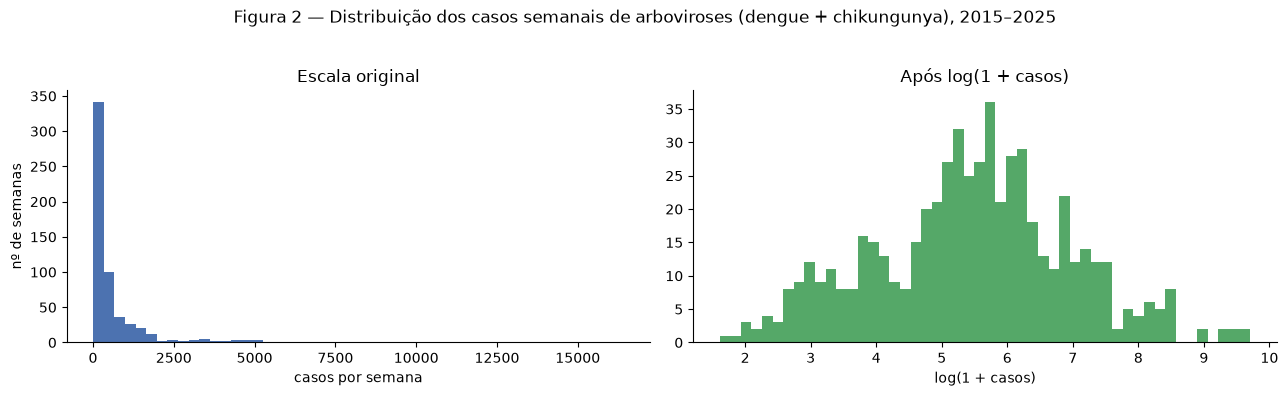

Assimetria: original = 5.81 | log = -0.02
λ de Box-Cox (máxima verossimilhança) = 0.005


In [15]:
y = np.log1p(casos).rename("y")
lambda_bc = stats.boxcox(casos.values + 1)[1]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(casos, bins=50, color="#4C72B0")
axes[0].set_title("Escala original"); axes[0].set_xlabel("casos por semana"); axes[0].set_ylabel("nº de semanas")
axes[1].hist(y, bins=50, color="#55A868")
axes[1].set_title("Após log(1 + casos)"); axes[1].set_xlabel("log(1 + casos)")
plt.suptitle("Figura 2 — Distribuição dos casos semanais de arboviroses (dengue + chikungunya), 2015–2025", y=1.03)
plt.tight_layout(); plt.show()
print(f"Assimetria: original = {stats.skew(casos):.2f} | log = {stats.skew(y):.2f}")
print(f"λ de Box-Cox (máxima verossimilhança) = {lambda_bc:.3f}")

**Análise:** Na escala original, a distribuição é fortemente assimétrica à direita: a maior parte das semanas tem poucas centenas de casos, e poucas semanas epidêmicas chegam a milhares. Esse formato faz a variância crescer com o nível da série, o que viola a hipótese de variância constante dos modelos ARIMA e faz as semanas de surto dominarem o ajuste. Após a transformação logarítmica, a assimetria cai bastante. O λ estimado fica próximo de zero (na Etapa 2, pelo método de Guerrero, obteve-se λ ≈ −0,02), o que confirma a escolha do logaritmo, que tem a vantagem de ser facilmente revertido (`exp(ŷ) − 1`) e interpretado. 

**Decisão:** todos os modelos são ajustados em `y = log(1 + casos)`, e as métricas são calculadas na escala original de casos.

## **5. Visão geral da série e segmentação por doença**

A Figura 3 mostra as três séries em escala logarítmica e a composição semanal do total.

A Figura 4 apresenta o total anual por doença.

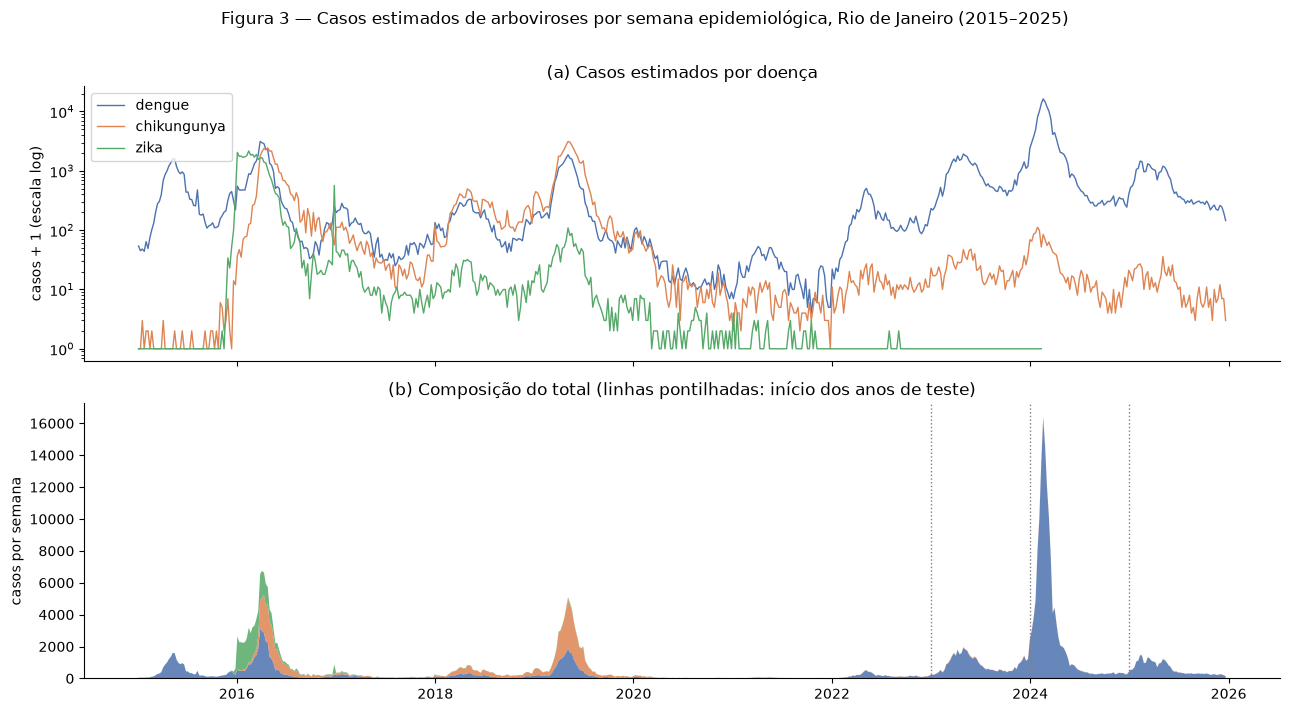

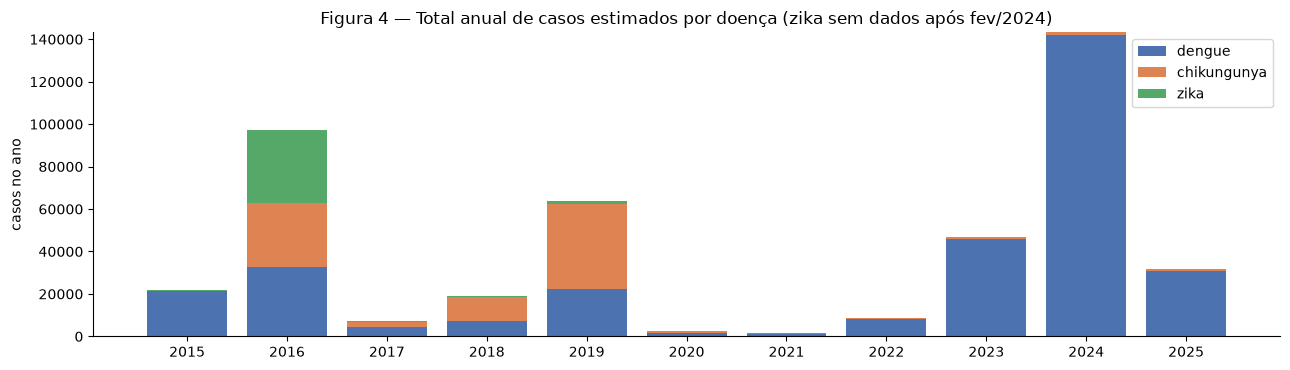

Totais anuais (casos estimados):


,dengue,chikungunya,zika,total alvo (dengue + chik.)
ano epidemiológico,,,,
2015,21437,57,593,21494
2016,32497,30422,34137,62919
2017,4506,2174,698,6680
2018,7465,11067,644,18532
2019,22410,40164,1232,62574
2020,1504,1130,83,2634
2021,1092,265,24,1357
2022,8053,599,2,8652
2023,45722,1175,0,46897


In [16]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
cores = {"dengue": "#4C72B0", "chikungunya": "#DD8452", "zika": "#55A868"}
for d in DOENCAS:
    axes[0].plot(casos_doencas.index, casos_doencas[d] + 1, lw=1, label=d, color=cores[d])
axes[0].set_yscale("log"); axes[0].set_ylabel("casos + 1 (escala log)"); axes[0].legend(loc="upper left")
axes[0].set_title("(a) Casos estimados por doença")
axes[1].stackplot(casos_doencas.index, *[casos_doencas[d].fillna(0) for d in DOENCAS],
                  labels=DOENCAS, colors=[cores[d] for d in DOENCAS], alpha=0.85)
for a in ANOS_TESTE:
    axes[1].axvline(inicio_ano_epi(a), color="grey", ls=":", lw=1)
axes[1].set_ylabel("casos por semana"); axes[1].set_title("(b) Composição do total (linhas pontilhadas: início dos anos de teste)")
plt.suptitle("Figura 3 — Casos estimados de arboviroses por semana epidemiológica, Rio de Janeiro (2015–2025)", y=1.01)
plt.tight_layout(); plt.show()

ano_epi, se = ano_e_semana_epi(casos_doencas.index)
anual = casos_doencas[DOENCAS].groupby(ano_epi).sum().round(0)
anual.index.name = "ano epidemiológico"
fig, ax = plt.subplots(figsize=(13, 3.8))
base = np.zeros(len(anual))
for d in DOENCAS:
    ax.bar(anual.index, anual[d], bottom=base, label=d, color=cores[d]); base += anual[d].values
ax.set_ylabel("casos no ano"); ax.legend(); ax.set_xticks(anual.index)
ax.set_title("Figura 4 — Total anual de casos estimados por doença (zika sem dados após fev/2024)")
plt.tight_layout(); plt.show()
anual["total alvo (dengue + chik.)"] = anual[DOENCAS_ALVO].sum(axis=1)
print("Totais anuais (casos estimados):")
anual.astype(int)

**Análise:** A série alterna anos de baixa transmissão com anos epidêmicos de intensidade muito diferente, e a doença dominante muda ao longo do tempo: a chikungunya teve surtos próprios, defasados em relação aos da dengue, e a zika concentra-se nos primeiros anos da série. No período em que as três séries existem (2015 a fevereiro de 2024), a dengue responde por cerca de 60% dos casos, a chikungunya por 28% e a zika por 12%. O ano de 2024 registrou a maior epidemia de dengue do período, seguido por um ano de baixa transmissão em 2025. Essa irregularidade tem duas consequências para a modelagem: (i) a sazonalidade anual existe, mas a amplitude varia muito de um ano para outro, o que favorece modelos capazes de se adaptar ao nível recente da série; e (ii) avaliar os modelos em um único ano seria frágil, já que um ano epidêmico e um ano calmo testam habilidades diferentes. 

**Decisão:** validação em três anos de perfis distintos (2023, 2024 e 2025).

## **6. Sazonalidade**

A Figura 5 apresenta um mapa de calor do logaritmo dos casos por ano e semana epidemiológica, e a Figura 6 mostra o perfil sazonal típico (mediana e intervalo interquartil por SE) junto com o perfil médio de temperatura e precipitação.

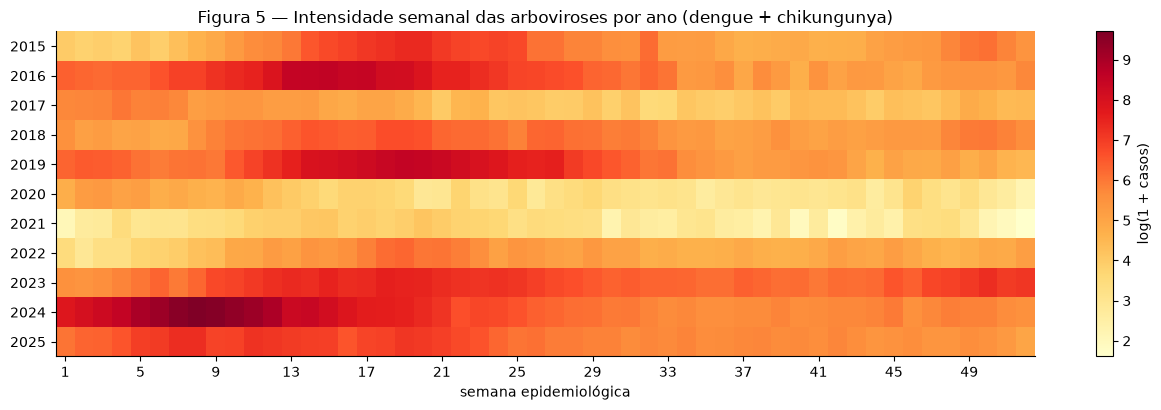

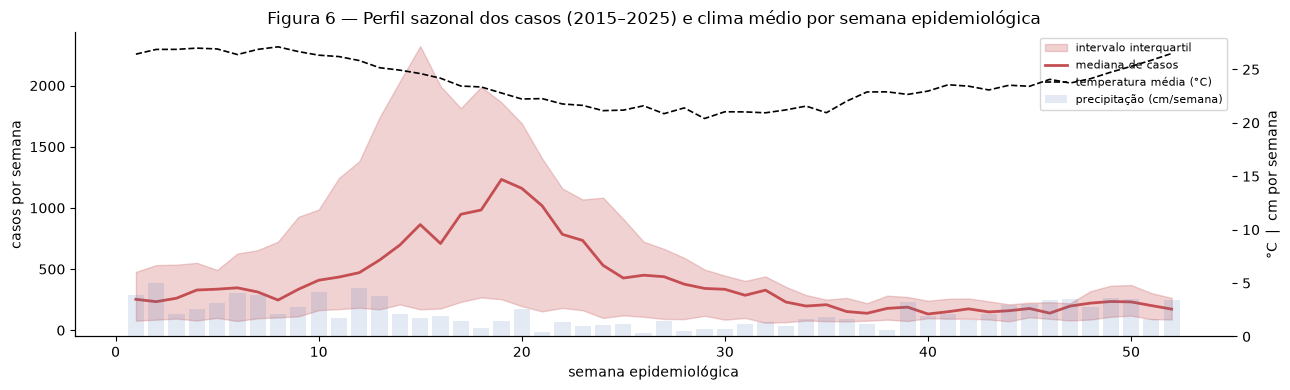

SE com maior mediana de casos: 19 | SE mais quente em média: 8 | SE mais chuvosa em média: 2


In [17]:
painel = pd.DataFrame({"ano": ano_epi, "se": se, "y": y.values}).query("se <= 52")
mapa = painel.pivot_table(index="ano", columns="se", values="y")
fig, ax = plt.subplots(figsize=(13, 4.2))
im = ax.imshow(mapa.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(mapa.index))); ax.set_yticklabels(mapa.index)
ax.set_xticks(range(0, 52, 4)); ax.set_xticklabels(mapa.columns[::4])
ax.set_xlabel("semana epidemiológica"); plt.colorbar(im, ax=ax, label="log(1 + casos)")
ax.set_title("Figura 5 — Intensidade semanal das arboviroses por ano (dengue + chikungunya)")
plt.tight_layout(); plt.show()

perfil = painel.groupby("se")["y"].quantile([0.25, 0.5, 0.75]).unstack()
clima_se = clima_alinhado.loc[casos.index].assign(se=se).query("se <= 52").groupby("se")[["temp_media", "precip_mm"]].mean()
fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.fill_between(perfil.index, np.expm1(perfil[0.25]), np.expm1(perfil[0.75]), alpha=0.25, color="#C44E52", label="intervalo interquartil")
ax1.plot(perfil.index, np.expm1(perfil[0.5]), color="#C44E52", lw=2, label="mediana de casos")
ax1.set_xlabel("semana epidemiológica"); ax1.set_ylabel("casos por semana")
ax2 = ax1.twinx()
ax2.plot(clima_se.index, clima_se["temp_media"], color="black", ls="--", lw=1.2, label="temperatura média (°C)")
ax2.bar(clima_se.index, clima_se["precip_mm"] / 10, alpha=0.15, color="#4C72B0", label="precipitação (cm/semana)")
ax2.set_ylabel("°C  |  cm por semana")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8)
ax1.set_title("Figura 6 — Perfil sazonal dos casos (2015–2025) e clima médio por semana epidemiológica")
plt.tight_layout(); plt.show()

se_pico = perfil[0.5].idxmax()
print(f"SE com maior mediana de casos: {se_pico} | SE mais quente em média: {clima_se['temp_media'].idxmax()} | "
      f"SE mais chuvosa em média: {clima_se['precip_mm'].idxmax()}")

**Análise.** O padrão sazonal é nítido: os casos sobem a partir do início do ano, atingem o máximo no fim do verão e no outono (aproximadamente entre as semanas 8 e 20, de fevereiro a maio) e caem para o mínimo no inverno. O pico típico dos casos ocorre algumas semanas depois do pico de temperatura e de chuva, o que é coerente com o ciclo do vetor 

*Aedes aegypti*: o calor e a água acumulada aceleram a reprodução do mosquito, e a transmissão e o adoecimento vêm depois. O mapa de calor também mostra que a sazonalidade varia em intensidade e em época: em alguns anos a temporada começa mais cedo (2024) e em outros quase não há temporada. 

**Decisão:** a sazonalidade anual deve estar presente nos modelos (termo sazonal de 52 semanas, termos de Fourier ou componente sazonal da suavização exponencial), e o clima deve ser testado com defasagem. 

## **7. Decomposição STL**

A decomposição STL (CLEVELAND et al., 1990) separa a série transformada em tendência, sazonalidade e resíduo, com período de 52 semanas e ajuste robusto a valores extremos (Figura 7). A Tabela 4 quantifica a força da tendência (F_T) e da sazonalidade (F_S), calculadas como em Wang, Smith e Hyndman (2006): valores próximos de 1 indicam componente forte; próximos de 0, componente fraco.

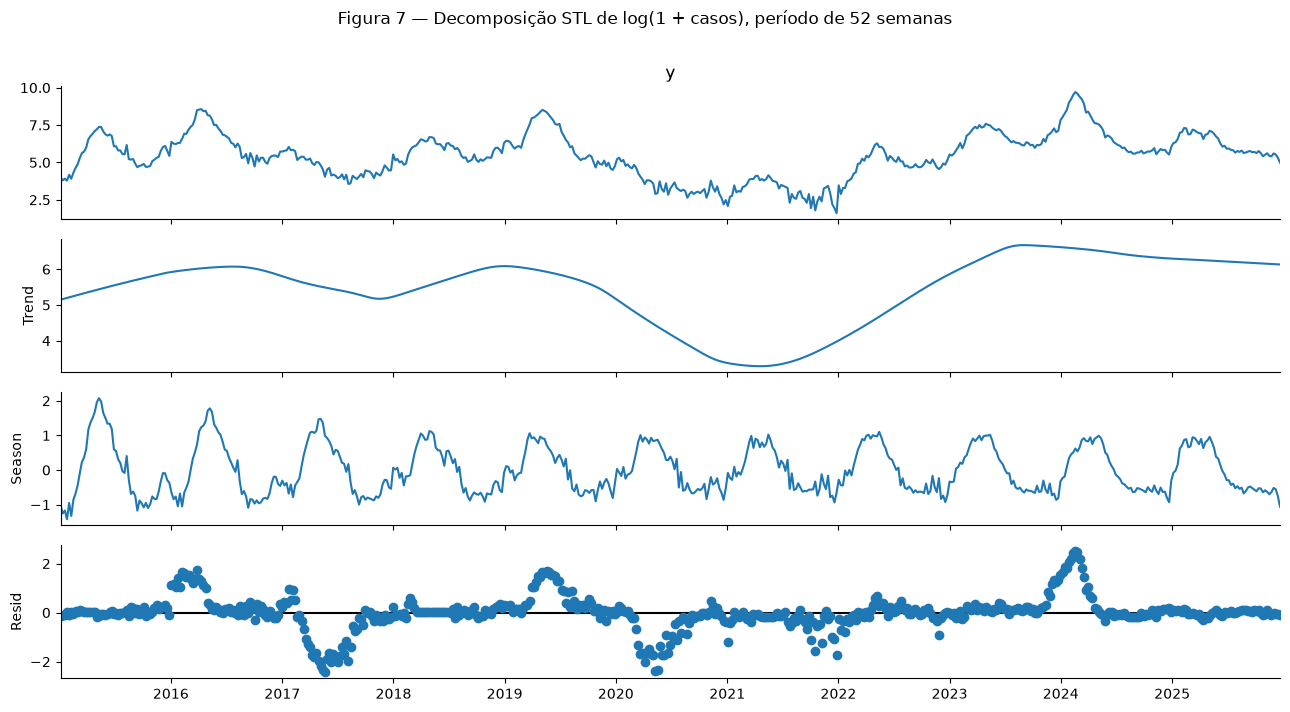

Tabela 4 — Força da tendência e da sazonalidade (STL, escala log)


,F_T (tendência),F_S (sazonalidade)
série,,
alvo (dengue + chikungunya),0.74,0.45
dengue (2015–2025),0.74,0.41
chikungunya (2015–2025),0.70,0.23
zika (2015–2024),0.57,0.18


In [18]:
def forca_componentes(serie, periodo=52):
    r = STL(serie, period=periodo, robust=True).fit()
    var_r = np.var(r.resid)
    return r, max(0.0, 1 - var_r / np.var(r.trend + r.resid)), max(0.0, 1 - var_r / np.var(r.seasonal + r.resid))


stl_alvo, ft_alvo, fs_alvo = forca_componentes(y)
fig = stl_alvo.plot()
fig.set_size_inches(13, 7)
fig.suptitle("Figura 7 — Decomposição STL de log(1 + casos), período de 52 semanas", y=1.01)
plt.tight_layout(); plt.show()

linhas = [{"série": "alvo (dengue + chikungunya)", "F_T (tendência)": ft_alvo, "F_S (sazonalidade)": fs_alvo}]
for d in DOENCAS:
    s_d = np.log1p(casos_doencas[d].dropna())
    _, ft, fs = forca_componentes(s_d)
    linhas.append({"série": f"{d} ({s_d.index.min().year}–{s_d.index.max().year})", "F_T (tendência)": ft, "F_S (sazonalidade)": fs})
tabela4 = pd.DataFrame(linhas).set_index("série").round(2)
print("Tabela 4 — Força da tendência e da sazonalidade (STL, escala log)")
tabela4

**Análise.** A componente de tendência da STL não é uma tendência de longo prazo crescente ou decrescente: ela captura os ciclos plurianuais de epidemia (anos de alta seguidos de anos de baixa), por isso F_T é alto (na Etapa 2, F_T ≈ 0,75). A sazonalidade anual é moderada (F_S ≈ 0,41): está presente todo ano, mas explica menos variação que os ciclos epidêmicos. O resíduo apresenta picos concentrados nos anos de surto, mostrando que a intensidade das epidemias não é previsível só pelo calendário. Na comparação entre doenças, a dengue e a chikungunya têm forças diferentes, o que indica dinâmicas próprias e ajuda a explicar por que a soma das duas é mais irregular que cada série isolada. 

**Decisões:** (i) um modelo puramente sazonal e determinístico (como o ingênuo sazonal ou só termos de Fourier) tende a errar em anos atípicos; (ii) modelos com componente autorregressivo, que acompanham o nível recente, são preferíveis.

## **8. Estacionariedade e autocorrelação**

A Tabela 5 apresenta os testes de Dickey-Fuller aumentado (ADF), cuja hipótese nula é de raiz unitária (série não estacionária), e de Kwiatkowski-Phillips-Schmidt-Shin (KPSS), cuja hipótese nula é de estacionariedade (DICKEY; FULLER, 1979; KWIATKOWSKI et al., 1992). Usar os dois testes evita conclusões baseadas em um único teste. A Figura 8 mostra as funções de autocorrelação (ACF) e de autocorrelação parcial (PACF) da série transformada.

Tabela 5 — Testes de estacionariedade em log(1 + casos)  (o KPSS limita o p-valor entre 0,01 e 0,10)


,estatística,p-valor,hipótese nula,conclusão (5%)
ADF,-3.6793,0.0044,raiz unitária (não estacionária),rejeita H0 → estacionária
KPSS,0.3450,0.1000,estacionária,não rejeita H0 → estacionária


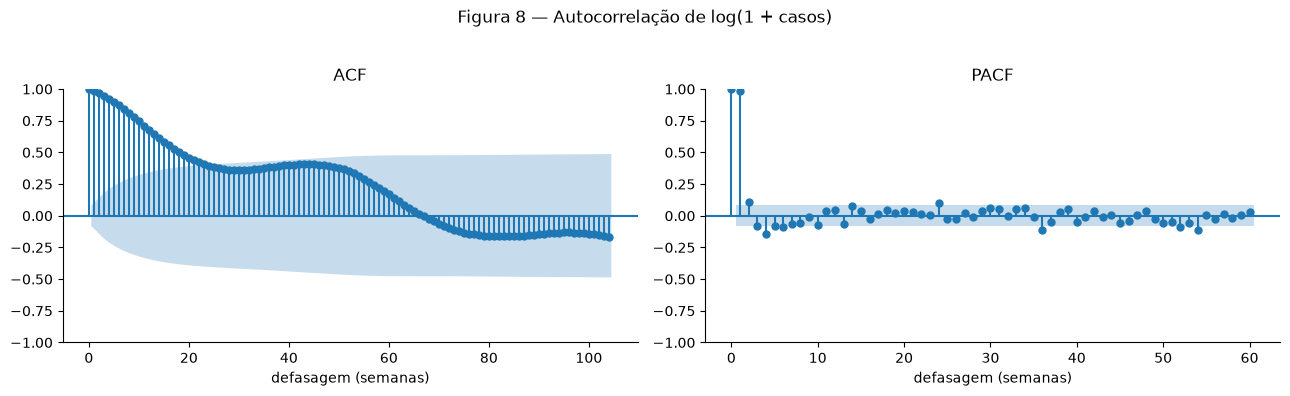

Autocorrelação nas defasagens 1, 2, 4, 13, 26 e 52 semanas: {1: 0.98, 2: 0.97, 4: 0.93, 13: 0.65, 26: 0.38, 52: 0.37}


In [19]:
adf = adfuller(y, autolag="AIC")
kp = kpss(y, regression="c", nlags="auto")
tabela5 = pd.DataFrame({
    "estatística": [adf[0], kp[0]],
    "p-valor": [adf[1], kp[1]],
    "hipótese nula": ["raiz unitária (não estacionária)", "estacionária"],
    "conclusão (5%)": ["rejeita H0 → estacionária" if adf[1] < 0.05 else "não rejeita H0 → indício de raiz unitária",
                       "rejeita H0 → indício de não estacionariedade" if kp[1] < 0.05 else "não rejeita H0 → estacionária"],
}, index=["ADF", "KPSS"]).round(4)
print("Tabela 5 — Testes de estacionariedade em log(1 + casos)  (o KPSS limita o p-valor entre 0,01 e 0,10)")
display(tabela5)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_acf(y, lags=104, ax=axes[0], title="ACF")
plot_pacf(y, lags=60, ax=axes[1], method="ywm", title="PACF")
for ax in axes:
    ax.set_xlabel("defasagem (semanas)")
plt.suptitle("Figura 8 — Autocorrelação de log(1 + casos)", y=1.03)
plt.tight_layout(); plt.show()
acf_valores = pd.Series([y.autocorr(k) for k in (1, 2, 4, 13, 26, 52)], index=[1, 2, 4, 13, 26, 52]).round(2)
print("Autocorrelação nas defasagens 1, 2, 4, 13, 26 e 52 semanas:", acf_valores.to_dict())

**Análise.** O ADF rejeita a hipótese de raiz unitária, como já observado na Etapa 2. Se o KPSS também indicar não estacionariedade, a leitura conjunta é de uma série estacionária em torno de ciclos longos, mas com dependência de longo alcance: ela volta ao seu patamar, porém devagar. A ACF confirma isso: a autocorrelação na defasagem de 1 semana é muito alta e decai lentamente, com um novo aumento perto de 52 semanas, que é a marca da sazonalidade anual. A PACF tem pico forte na defasagem 1 e corte rápido depois, padrão típico de um processo autorregressivo de baixa ordem. 

**Decisões:** (i) modelos sem diferenciação (d = 0), com termos autorregressivos de ordem baixa e termo sazonal; (ii) a alta autocorrelação de curto prazo significa que repetir o último valor observado (persistência) já é uma previsão difícil de superar em horizontes curtos, por isso a persistência é o baseline principal.

## **9. Picos por ano e por doença**

A Tabela 6 apresenta a semana e a magnitude do pico de cada doença em cada ano epidemiológico. Para a gestão de leitos, a época e a intensidade do pico são mais importantes que o total anual.

In [20]:
linhas = []
for d in DOENCAS_ALVO + [ALVO]:
    s_d = casos_doencas[d]
    for ano in sorted(set(ano_epi)):
        trecho = s_d[ano_epi == ano].dropna()
        if len(trecho) < 40:
            continue
        semana = trecho.idxmax()
        linhas.append({"ano": ano, "série": d, "SE do pico": int(ano_e_semana_epi([semana])[1][0]),
                       "casos no pico": int(round(trecho.max()))})
tabela6 = pd.DataFrame(linhas).pivot_table(index="ano", columns="série", values=["SE do pico", "casos no pico"])
tabela6 = tabela6.reindex(columns=[(m, s) for m in ["SE do pico", "casos no pico"] for s in DOENCAS_ALVO + [ALVO]])
print("Tabela 6 — Semana epidemiológica e magnitude do pico por ano")
display(tabela6.astype(int))
print("Correlação entre as séries de dengue e chikungunya (log):",
      round(np.log1p(casos_doencas["dengue"]).corr(np.log1p(casos_doencas["chikungunya"])), 2))

Tabela 6 — Semana epidemiológica e magnitude do pico por ano


SE do pico                         casos no pico                        
série     dengue chikungunya arboviroses        dengue chikungunya arboviroses
ano                                                                           
2015          19          51          19          1598          13        1598
2016          13          17          15          3127        2433        5237
2017           4           4           4           282         135         417
2018          19          18          18           331         494         807
2019          19          19          19          1864        3122        4986
2020           3           5           3           109          97         202
2021          14          18          20            52          13          62
2022          19          19          19           505          26         531
2023          18          22          18          1919          47        1965
2024           8           5           8         16339         111       16423
2025           7          19           7          1457          35        1483

Correlação entre as séries de dengue e chikungunya (log): 0.27


**Análise.** Os picos da série-alvo se concentram, na maioria dos anos, entre o fim do verão e o outono, mas a semana do pico varia em várias semanas de um ano para outro (por exemplo, em 2024 o pico veio no fim de fevereiro, bem antes do habitual; em 2023, no fim de abril). A magnitude varia em mais de uma ordem de grandeza. Dengue e chikungunya nem sempre têm pico no mesmo ano ou na mesma semana, o que confirma que são epidemias com dinâmicas próprias. 

**Decisões:** (i) além do erro médio, os modelos são avaliados pela capacidade de antecipar o pico e a entrada em alerta (Seção de Resultados); (ii) a modelagem da soma favorece a demanda hospitalar total, e a modelagem por doença fica como extensão (basta alterar `ALVO`).

## **10. Relação entre clima e casos**

A Figura 9 apresenta a correlação de Pearson entre o logaritmo dos casos e cada variável climática defasada de 0 a 20 semanas. Para não usar informação dos anos de teste em uma decisão de modelagem, a análise considera apenas os dados de 2015 a 2022. A área cinza marca as defasagens menores que o horizonte de previsão (H = 4): uma variável climática só pode entrar no modelo se já tiver sido observada no momento da previsão.

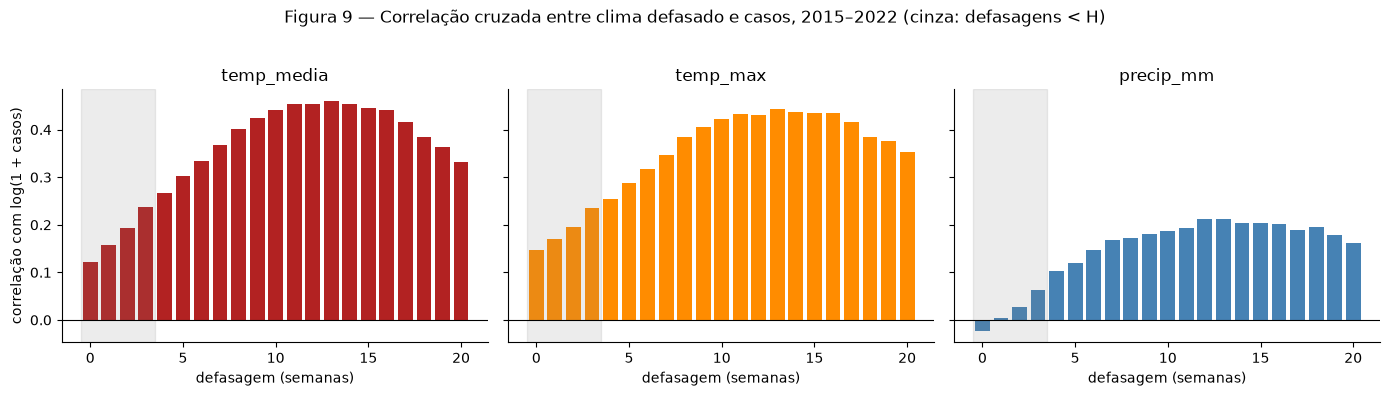

Resumo da correlação cruzada:


,defasagem de maior |r|,r,r na defasagem 4
temp_media,13,0.461,0.267
temp_max,13,0.443,0.255
precip_mm,13,0.213,0.104


In [21]:
def correlacao_por_defasagem(alvo, preditor, max_lag=MAX_LAG_CLIMA):
    res = {}
    for lag in range(0, max_lag + 1):
        d = pd.concat([alvo, preditor.shift(lag)], axis=1).dropna()
        res[lag] = pearsonr(d.iloc[:, 0], d.iloc[:, 1])[0]
    return pd.Series(res)


y_eda = y[y.index < inicio_ano_epi(FIM_EDA_CLIMA + 1)]
corr_eda = pd.DataFrame({v: correlacao_por_defasagem(y_eda, clima_alinhado[v], max_lag=20)
                         for v in ["temp_media", "temp_max", "precip_mm"]})
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (v, cor) in zip(axes, [("temp_media", "firebrick"), ("temp_max", "darkorange"), ("precip_mm", "steelblue")]):
    ax.bar(corr_eda.index, corr_eda[v], color=cor)
    ax.axvspan(-0.5, H - 0.5, color="grey", alpha=0.15)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(v); ax.set_xlabel("defasagem (semanas)")
axes[0].set_ylabel("correlação com log(1 + casos)")
plt.suptitle(f"Figura 9 — Correlação cruzada entre clima defasado e casos, 2015–{FIM_EDA_CLIMA} (cinza: defasagens < H)", y=1.03)
plt.tight_layout(); plt.show()
melhor = pd.DataFrame({"defasagem de maior |r|": corr_eda.abs().idxmax(), "r": corr_eda.apply(lambda s: s.loc[s.abs().idxmax()]),
                       "r na defasagem 4": corr_eda.loc[4]}).round(3)
print("Resumo da correlação cruzada:")
melhor

**Análise.** A temperatura tem correlação positiva com os casos, que cresce com a defasagem e atinge o máximo por volta de 10 a 12 semanas (r ≈ 0,45 na Etapa 2). Isso é coerente com o tempo necessário para o desenvolvimento do mosquito, o período de incubação do vírus no vetor e no ser humano e o acúmulo de transmissão. A temperatura máxima segue o mesmo padrão. A precipitação tem correlação fraca (|r| abaixo de 0,2) em todas as defasagens: a chuva semanal acumulada é um indicador ruidoso dos criadouros, que dependem também de armazenamento de água e saneamento. É importante notar que boa parte da correlação da temperatura vem do fato de os dois fenômenos serem sazonais; parte dessa informação já está contida no calendário. 

**Decisões:** (i) o clima entra nos modelos apenas com defasagem ≥ H, escolhida só com os dados de treino de cada ano de teste; (ii) para medir o ganho real do clima, o ARIMAX é testado com e sem clima. 

## **11. Segmentação territorial (Áreas de Planejamento)**

A base também pode ser segmentada pelas 10 AP do município. Os casos notificados por AP vêm do Tabnet Municipal da SMS-Rio e têm duas limitações importantes para a modelagem: estão disponíveis apenas com granularidade mensal (e não por semana epidemiológica) e, na base obtida até agora, apenas para dengue a partir de 2023. Por isso, a previsão é feita na escala municipal semanal, com série longa, e a distribuição entre as AP é feita depois, pela participação histórica de cada área nos casos (abordagem *top-down*). A análise exploratória por AP (participação de cada área, estabilidade dessa participação ao longo do tempo e incidência por 100 mil habitantes) virá na Etapa 4

## **12. Síntese da análise exploratória**

A Tabela 7 resume como cada achado da análise exploratória orientou as escolhas de modelagem.

**Tabela 7 — Achados da análise exploratória e decisões de modelagem**

| Achado | Evidência | Decisão de modelagem |
|---|---|---|
| Zika sem dados após fev/2024 | Tabela 2 | Alvo = dengue + chikungunya; zika apenas descritiva |
| Defasagem oculta de 1 semana na junção do clima | Tabela 3 | Clima agregado de domingo a sábado (`W-SAT`) |
| Distribuição muito assimétrica, variância cresce com o nível | Figura 2, λ ≈ 0 | Modelagem em `log(1 + casos)`; métricas na escala original |
| Anos epidêmicos irregulares e de intensidade muito variável | Figuras 3–5, Tabela 6 | Validação em três anos de perfis distintos (2023–2025) |
| Sazonalidade anual clara, mas de amplitude variável | Figuras 5–7, Tabela 4 | Termo sazonal (S = 52, Fourier ou Holt-Winters) combinado com componente que acompanha o nível recente |
| Série estacionária com autocorrelação alta e persistente | Tabela 5, Figura 8 | d = 0, termos autorregressivos de baixa ordem; persistência como baseline principal |
| Picos com época e intensidade variáveis | Tabela 6 | Avaliação também pela antecipação do pico e do alerta |
| Temperatura correlacionada com 10–12 semanas de defasagem; chuva fraca | Figura 9 | Clima com defasagem ≥ H; teste com e sem clima |
| Dados por AP só mensais e recentes | Seção 11 | Previsão municipal semanal + desagregação *top-down* por AP |

# **Modelos**

Com a série caracterizada, esta seção atende ao objetivo específico OE3: levantar as técnicas adequadas ao problema, justificar as escolhas a partir da análise exploratória, implementar os modelos e explorar seus hiperparâmetros. Seguindo a orientação da disciplina de que trabalhos de pesquisa devem comparar técnicas, já que não há como saber de antemão qual se ajusta melhor a uma série de saúde, foram implementadas cinco técnicas de famílias diferentes, além de dois baselines.

## **1. Levantamento das técnicas**

A Tabela 8 relaciona as principais técnicas usadas na previsão de séries epidemiológicas e indica quais foram empregadas, com a justificativa baseada nas características observadas na EDA.

**Tabela 8 — Técnicas levantadas e escolhas para a modelagem**

| Técnica | Família | Como trata a sazonalidade | Variáveis exógenas | Vantagens | Limitações | Usada? Justificativa |
|---|---|---|---|---|---|---|
| Persistência e ingênuo sazonal | Baseline | Ingênuo sazonal repete a mesma semana do ano anterior | Não | Referências mínimas que qualquer modelo deve superar (HYNDMAN; ATHANASOPOULOS, 2021) | Não antecipam mudanças | **Sim**, como referência; a persistência é exigente porque a autocorrelação de curto prazo é alta (Figura 8) |
| SARIMA/SARIMAX | Estatística (Box-Jenkins) | Termos autorregressivos e de média móvel sazonais (S = 52) | Sim | Interpretável, intervalos de previsão, acompanha o nível recente; validado em dengue (MARTINEZ; SILVA, 2011) | Relações lineares; S = 52 é lento de estimar | **Sim, modelo base**: série estacionária, AR de baixa ordem e pico em 52 na ACF |
| Regressão harmônica dinâmica (ARIMAX com Fourier) | Estatística | Pares seno/cosseno com período de 52,18 semanas | Sim | Leve e flexível para períodos longos ou não inteiros (HYNDMAN; ATHANASOPOULOS, 2021) | Sazonalidade determinística, igual todo ano | **Sim**: alternativa mais leve ao S = 52 e base para testar o ganho do clima |
| Suavização exponencial (Holt-Winters) | Estatística | Componente sazonal atualizado a cada semana | Não | Simples, adapta nível e sazonalidade ao longo do tempo (WINTERS, 1960) | Sem exógenas; sazonalidade de 52 semanas exige muitos estados iniciais | **Sim**: família diferente do ARIMA, adequada a sazonalidade de amplitude variável (Figura 5) |
| Prophet | Estatística (aditiva) | Termos de Fourier e tendência por partes | Sim | Fácil de usar, robusto a lacunas (TAYLOR; LETHAM, 2018) | Sazonalidade determinística, semelhante ao ARIMAX com Fourier | Não: redundante com a regressão harmônica já testada |
| *Gradient Boosting* com defasagens | Aprendizado de máquina | Atributo de calendário (Fourier) e valor do ano anterior | Sim | Captura não linearidades e interações (FRIEDMAN, 2001) | Não extrapola além do observado; poucos dados semanais | **Sim**: testa se relações não lineares melhoram a previsão |
| LSTM | Aprendizado profundo | Aprendida a partir de janelas de 26 semanas e atributos de calendário | Sim | Dependências não lineares e de longo prazo (HOCHREITER; SCHMIDHUBER, 1997); promissora em dengue (SAHD et al., 2026) | Precisa de muitos dados; sensível a hiperparâmetros e à semente | **Sim, exploratória**: comparação prevista no objetivo do projeto |

## **2. Bibliotecas e funções**

A Tabela 9 apresenta os pacotes e as funções usados na construção e no treinamento dos modelos.

**Tabela 9 — Bibliotecas e funções utilizadas**

| Biblioteca | Funções e classes | Uso |
|---|---|---|
| `statsmodels` (SEABOLD; PERKTOLD, 2010) | `SARIMAX`, `.fit()`, `.append(refit=False)`, `.get_forecast()` | SARIMAX e ARIMAX com Fourier; atualização semanal do estado sem reestimar parâmetros; previsões com intervalo |
| `statsmodels` | `ExponentialSmoothing` | Estimação dos parâmetros do Holt-Winters |
| `statsmodels` | `STL`, `adfuller`, `kpss`, `plot_acf`, `plot_pacf` | Análise exploratória |
| `scikit-learn` (PEDREGOSA et al., 2011) | `HistGradientBoostingRegressor` | *Gradient Boosting* com estratégia direta (um modelo por horizonte) |
| `PyTorch` (PASZKE et al., 2019) | `nn.LSTM`, `nn.Linear`, `optim.Adam` | LSTM com saída multi-horizonte e parada antecipada |
| `pandas`, `numpy`, `scipy`, `matplotlib` | — | Manipulação, testes estatísticos e gráficos |

## **3. Protocolo de validação**

- **Validação *walk-forward* com origem móvel em três anos (2023, 2024 e 2025).** Para cada ano de teste, tudo o que depende de dados (escolha das defasagens climáticas, padronização, ordem do modelo, hiperparâmetros e parâmetros) é definido apenas com as semanas anteriores ao início daquele ano, sem vazamento de informação.
- **Uso simulado.** Durante o ano de teste, os parâmetros ficam fixos, e a cada semana o modelo recebe o valor observado e prevê as próximas 1 a 4 semanas.
- **Métricas** (na escala original de casos): erro absoluto médio (MAE), raiz do erro quadrático médio (RMSE), erro percentual absoluto ponderado (WAPE = soma dos erros absolutos ÷ soma dos casos observados) e ganho percentual do MAE em relação à persistência. Para os modelos com intervalo, a cobertura empírica do intervalo de 80%. Para a leitura operacional, acerto do nível de alerta e antecedência na entrada em alerta.

## **4. Preparação de cada ano de teste e baselines**

In [22]:
def termos_fourier(index, periodo=PERIODO, K=K_FOURIER, origem=pd.Timestamp("2015-01-04")):
    t = ((index - origem).days / 7).values
    cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * t / periodo)
        cols[f"cos{k}"] = np.cos(2 * np.pi * k * t / periodo)
    return pd.DataFrame(cols, index=index)


def preparar_fold(ano):
    """Tudo o que depende do treino de um ano de teste: máscaras, defasagens, exógenas, ordem do ARIMAX e limiares."""
    ini, fim = inicio_ano_epi(ano), inicio_ano_epi(ano + 1)
    treino = np.asarray(y.index < ini)
    teste = np.asarray((y.index >= ini) & (y.index < fim))

    correlacoes = {v: correlacao_por_defasagem(y[treino], clima_alinhado[v]) for v in ["temp_media", "precip_mm"]}
    lags = {v: int(s.loc[H:].abs().idxmax()) for v, s in correlacoes.items()}

    X_clima = pd.DataFrame({f"{v}_lag{L}": clima_alinhado[v].shift(L) for v, L in lags.items()}).reindex(y.index)
    X_clima = (X_clima - X_clima[treino].mean()) / X_clima[treino].std()
    X_fourier = termos_fourier(y.index)
    X_fourier_clima = pd.concat([X_fourier, X_clima], axis=1)
    assert not X_fourier_clima[treino | teste].isna().any().any(), "NaN nas exógenas"

    aic = []
    for p in range(0, 3):
        for q in range(0, 3):
            try:
                r = SARIMAX(y[treino], exog=X_fourier_clima[treino], order=(p, 0, q), trend="c").fit(disp=False)
                aic.append({"ano de teste": ano, "p": p, "q": q, "AIC": r.aic})
            except Exception as e:
                print(f"  ({ano}) p={p}, q={q} falhou: {e}")
    aic = pd.DataFrame(aic).sort_values("AIC").reset_index(drop=True)
    ordem = (int(aic.p[0]), 0, int(aic.q[0]))
    limiares = casos[treino].quantile(list(QUANTIS_ALERTA)).values
    return dict(ano=ano, treino=treino, teste=teste, correlacoes=correlacoes, lags=lags, ordem=ordem, aic=aic,
                X_clima=X_clima, X_fourier=X_fourier, X_fourier_clima=X_fourier_clima, limiares=limiares)


def origens_do_fold(f):
    """1ª origem = última semana do treino; depois, cada semana do teste exceto a última."""
    idx_teste = y.index[f["teste"]]
    return [y.index[f["treino"]][-1]] + list(idx_teste[:-1])


def futuros_da_origem(f, origem):
    pos = y.index.get_loc(origem)
    fim_teste = y.index[f["teste"]][-1]
    return pos, [d for d in y.index[pos + 1: pos + 1 + H] if d <= fim_teste]


def linha(f, nome, origem, alvo, h, previsto, ic_inf=np.nan, ic_sup=np.nan):
    return {"ano_teste": f["ano"], "modelo": nome, "origem": origem, "alvo": alvo, "h": h,
            "previsto": float(previsto), "ic_inf": ic_inf, "ic_sup": ic_sup}


def baselines(f):
    linhas = []
    for origem in origens_do_fold(f):
        pos, futuros = futuros_da_origem(f, origem)
        for h, alvo in enumerate(futuros, start=1):
            linhas.append(linha(f, "Ingênuo sazonal", origem, alvo, h, casos.iloc[pos + h - 52]))
            linhas.append(linha(f, "Persistência", origem, alvo, h, casos.iloc[pos]))
    return pd.DataFrame(linhas)


t0 = time.time()
folds = {ano: preparar_fold(ano) for ano in ANOS_TESTE}
for ano, f in folds.items():
    print(f"[{ano}] treino até {y.index[f['treino']][-1].date()} ({f['treino'].sum()} semanas) | "
          f"defasagens do clima {f['lags']} | ordem ARIMAX {f['ordem']} | limiares Atenção/Crítico {f['limiares'].round(0)}")
print(f"Preparação concluída em {time.time() - t0:.0f} s")

[2023] treino até 2022-12-25 (417 semanas) | defasagens do clima {'temp_media': 12, 'precip_mm': 12} | ordem ARIMAX (2, 0, 0) | limiares Atenção/Crítico [408. 971.]
[2024] treino até 2023-12-24 (469 semanas) | defasagens do clima {'temp_media': 11, 'precip_mm': 12} | ordem ARIMAX (2, 0, 0) | limiares Atenção/Crítico [ 517. 1279.]
[2025] treino até 2024-12-22 (521 semanas) | defasagens do clima {'temp_media': 11, 'precip_mm': 12} | ordem ARIMAX (2, 0, 0) | limiares Atenção/Crítico [ 548. 1602.]
Preparação concluída em 30 s


## **5. Modelo base: SARIMAX sazonal com clima defasado**

O SARIMAX(p, d, q)(P, D, Q)₅₂ modela o logaritmo dos casos como função dos próprios valores passados, de erros passados e dos mesmos termos 52 semanas antes, mais as variáveis climáticas defasadas e padronizadas. Pela EDA, usou-se d = D = 0 (série estacionária). A Tabela 10 apresenta a busca da configuração por AIC (critério de informação de Akaike) no treino do primeiro ano de teste (até 2022). O SARIMAX(1,0,1)(1,0,0)₅₂, definido como modelo base, é sempre avaliado; se outra configuração tiver menor AIC, ela também entra na comparação, para verificar se o melhor ajuste dentro da amostra se traduz em melhor previsão fora dela.

A mesma função de previsão *walk-forward* é usada pelo ARIMAX com termos de Fourier, cuja ordem (p, q) é escolhida por AIC em cada ano de teste (Tabela 11).

In [23]:
def nome_sarima(ordem, sazonal):
    return f"SARIMAX({ordem[0]},{ordem[1]},{ordem[2]})({sazonal[0]},{sazonal[1]},{sazonal[2]})52 + clima"


def walk_forward(f, X, ordem, ordem_sazonal=(0, 0, 0, 0), trend="c", nome="modelo"):
    treino = f["treino"]
    res = SARIMAX(y[treino], exog=None if X is None else X[treino],
                  order=ordem, seasonal_order=ordem_sazonal, trend=trend).fit(disp=False)
    linhas = []
    for i, origem in enumerate(origens_do_fold(f)):
        if i > 0:   # incorpora a semana recém-observada, sem reestimar parâmetros
            res = res.append(y.loc[[origem]], exog=None if X is None else X.loc[[origem]], refit=False)
        pos, futuros = futuros_da_origem(f, origem)
        if not futuros:
            break
        fc = res.get_forecast(steps=len(futuros), exog=None if X is None else X.loc[futuros])
        media = np.clip(np.expm1(np.asarray(fc.predicted_mean)), 0, None)
        ic = np.clip(np.expm1(np.asarray(fc.conf_int(alpha=ALPHA_IC))), 0, None)   # quantis: invariantes à transformação
        for h, alvo in enumerate(futuros, start=1):
            linhas.append(linha(f, nome, origem, alvo, h, media[h - 1], ic[h - 1, 0], ic[h - 1, 1]))
    return pd.DataFrame(linhas)


SARIMA_BASE = ((1, 0, 1), (1, 0, 0, 52))
CANDIDATOS_SARIMA = [SARIMA_BASE, ((1, 0, 0), (1, 0, 0, 52)), ((2, 0, 0), (1, 0, 0, 52)), ((1, 0, 1), (0, 0, 1, 52))]
modelos_sarima = [SARIMA_BASE]
if RODAR_SARIMA_52:
    f0 = folds[ANOS_TESTE[0]]
    busca = []
    for ordem, sazonal in CANDIDATOS_SARIMA:
        t0 = time.time()
        try:
            r = SARIMAX(y[f0["treino"]], exog=f0["X_clima"][f0["treino"]], order=ordem, seasonal_order=sazonal,
                        trend="c").fit(disp=False)
            busca.append({"configuração": nome_sarima(ordem, sazonal).replace(" + clima", ""), "AIC": r.aic,
                          "BIC": r.bic, "tempo (s)": time.time() - t0, "_cfg": (ordem, sazonal)})
        except Exception as e:
            print(f"{ordem}{sazonal} falhou: {e}")
    tabela10 = pd.DataFrame(busca).sort_values("AIC").reset_index(drop=True)
    melhor_aic = tabela10.loc[0, "_cfg"]
    if melhor_aic != SARIMA_BASE:
        modelos_sarima.append(melhor_aic)
    print(f"Tabela 10 — Busca da configuração do SARIMAX por AIC (treino até {ANOS_TESTE[0] - 1}, clima defasado como exógena)")
    display(tabela10.drop(columns="_cfg").round(1))
    print("Configurações avaliadas na validação:", [nome_sarima(*c) for c in modelos_sarima])

Tabela 10 — Busca da configuração do SARIMAX por AIC (treino até 2022, clima defasado como exógena)


,configuração,AIC,BIC,tempo (s)
0,"SARIMAX(2,0,0)(1,0,0)52",222.2,250.4,17.6
1,"SARIMAX(1,0,1)(1,0,0)52",224.3,252.6,16.3
2,"SARIMAX(1,0,1)(0,0,1)52",224.4,252.6,9.0
3,"SARIMAX(1,0,0)(1,0,0)52",233.3,257.5,14.4


Configurações avaliadas na validação: ['SARIMAX(1,0,1)(1,0,0)52 + clima', 'SARIMAX(2,0,0)(1,0,0)52 + clima']


## **6. Suavização exponencial (Holt-Winters)**

O Holt-Winters aditivo, aplicado ao logaritmo dos casos, mantém um nível e 52 estados sazonais, atualizados a cada semana com pesos α (nível) e γ (sazonalidade). Como a EDA indicou ausência de tendência de longo prazo, o componente de tendência não foi usado. Os parâmetros são estimados por máxima verossimilhança no treino de cada ano de teste (Tabela 12); no teste, a recursão é atualizada semana a semana com os parâmetros fixos, como nos demais modelos.

In [24]:
def estimar_holt_winters(y_treino):
    m = ExponentialSmoothing(np.asarray(y_treino), trend=None, seasonal="add", seasonal_periods=52,
                             initialization_method="estimated").fit()
    p = m.params
    par = dict(alpha=float(p["smoothing_level"]), gamma=float(p["smoothing_seasonal"]),
               l0=float(p["initial_level"]), s0=np.asarray(p["initial_seasons"], dtype=float))
    return par, np.asarray(m.fittedvalues)


def filtro_holt_winters(valores, par, m=52):
    """Recursão aditiva sem tendência. s[k] é o estado sazonal usado na observação k."""
    nivel, s = par["l0"], list(par["s0"])
    um_passo = np.empty(len(valores))
    for t, v in enumerate(valores):
        sazonal = s[t]
        um_passo[t] = nivel + sazonal
        novo_nivel = par["alpha"] * (v - sazonal) + (1 - par["alpha"]) * nivel
        s.append(par["gamma"] * (v - nivel) + (1 - par["gamma"]) * sazonal)
        nivel = novo_nivel
    return nivel, s, um_passo


def walk_forward_holt_winters(f, nome="Holt-Winters aditivo"):
    treino = f["treino"]
    par, ajustados = estimar_holt_winters(y[treino])
    _, _, um_passo = filtro_holt_winters(y[treino].values, par)
    recursao_ok = np.max(np.abs(um_passo - ajustados)) < 1e-6
    linhas = []
    for origem in origens_do_fold(f):
        pos, futuros = futuros_da_origem(f, origem)
        if not futuros:
            break
        historico = y.values[: pos + 1]
        if recursao_ok:
            nivel, s, _ = filtro_holt_winters(historico, par)
            prev_log = [nivel + s[pos + h] for h in range(1, len(futuros) + 1)]
        else:   # convenção diferente da biblioteca: usa o próprio statsmodels com os parâmetros fixos
            prev_log = ExponentialSmoothing(historico, trend=None, seasonal="add", seasonal_periods=52,
                                            initialization_method="known", initial_level=par["l0"],
                                            initial_seasonal=par["s0"]).fit(
                smoothing_level=par["alpha"], smoothing_seasonal=par["gamma"], optimized=False).forecast(len(futuros))
        for h, alvo in enumerate(futuros, start=1):
            linhas.append(linha(f, nome, origem, alvo, h, max(np.expm1(prev_log[h - 1]), 0)))
    info = {"ano de teste": f["ano"], "α (nível)": par["alpha"], "γ (sazonalidade)": par["gamma"],
            "recursão própria confere com a biblioteca": recursao_ok}
    return pd.DataFrame(linhas), info

## **7. *Gradient Boosting* com atributos de defasagem**

O *Gradient Boosting* (FRIEDMAN, 2001) combina sequencialmente árvores de decisão rasas, cada uma corrigindo o erro das anteriores. Para usá-lo em séries temporais, a série é transformada em uma tabela de atributos conhecidos no momento da previsão: os últimos oito valores de `log(1 + casos)`, médias móveis de 4 e 12 semanas, variações de 1 e 4 semanas, o valor da mesma semana do ano anterior, médias de 4 semanas de temperatura e chuva (atuais e 8 semanas antes) e os termos de Fourier da semana-alvo. Usa-se a estratégia direta: um modelo por horizonte h, que prevê a variação `y(t+h) − y(t)`; prever a variação, e não o nível, contorna a incapacidade das árvores de extrapolar para valores maiores que os vistos no treino.

Os hiperparâmetros (profundidade máxima, taxa de aprendizado e número de árvores) são escolhidos em cada ano de teste por busca em grade, usando as últimas 52 semanas do treino como validação (Tabela 13).

In [25]:
def atributos_base():
    X = pd.DataFrame(index=y.index)
    for k in range(8):
        X[f"y_lag{k}"] = y.shift(k)
    X["y_media4"], X["y_media12"] = y.rolling(4).mean(), y.rolling(12).mean()
    X["y_dif1"], X["y_dif4"] = y.diff(1), y.diff(4)
    for v in ["temp_media", "precip_mm"]:
        media4 = clima_alinhado[v].rolling(4).mean()
        X[f"{v}_media4"] = media4.reindex(y.index)
        X[f"{v}_media4_lag8"] = media4.shift(8).reindex(y.index)
    return X


X_BASE_GBM = atributos_base()


def atributos_horizonte(h):
    X = X_BASE_GBM.copy()
    X["y_mesma_semana_ano_anterior"] = y.shift(52 - h)
    fourier_alvo = termos_fourier(y.index + pd.Timedelta(weeks=h))
    fourier_alvo.index = y.index
    X = pd.concat([X, fourier_alvo.add_suffix("_alvo")], axis=1)
    return X, (y.shift(-h) - y)


GRADE_GBM = [dict(max_depth=d, learning_rate=lr, max_iter=n) for d in (2, 3, 5) for lr in (0.03, 0.1) for n in (200, 500)]


def novo_gbm(cfg):
    return HistGradientBoostingRegressor(max_depth=int(cfg["max_depth"]), learning_rate=float(cfg["learning_rate"]),
                                         max_iter=int(cfg["max_iter"]), min_samples_leaf=20,
                                         early_stopping=False, random_state=SEMENTE)


def walk_forward_gbm(f, nome="Gradient Boosting"):
    pos_fim_treino = int(np.where(f["treino"])[0][-1])
    posicoes = np.arange(len(y))
    dados_h = {}
    for h in range(1, H + 1):
        X, alvo = atributos_horizonte(h)
        validas = (X.notna().all(axis=1) & alvo.notna()).values & (posicoes + h <= pos_fim_treino)
        dados_h[h] = (X, alvo, np.where(validas)[0])

    grade = []
    for cfg in GRADE_GBM:
        erros = []
        for h, (X, alvo, idx) in dados_h.items():
            ajuste, val = idx[:-52], idx[-52:]
            mdl = novo_gbm(cfg).fit(X.iloc[ajuste], alvo.iloc[ajuste])
            prev = np.expm1(y.values[val] + mdl.predict(X.iloc[val]))
            erros.append(np.mean(np.abs(prev - casos.values[val + h])))
        grade.append({"ano de teste": f["ano"], **cfg, "MAE validação (casos)": np.mean(erros)})
    grade = pd.DataFrame(grade).sort_values("MAE validação (casos)").reset_index(drop=True)
    melhor = grade.iloc[0].to_dict()
    modelos = {h: novo_gbm(melhor).fit(X.iloc[idx], alvo.iloc[idx]) for h, (X, alvo, idx) in dados_h.items()}

    linhas = []
    for origem in origens_do_fold(f):
        pos, futuros = futuros_da_origem(f, origem)
        for h, alvo_data in enumerate(futuros, start=1):
            variacao = modelos[h].predict(dados_h[h][0].iloc[[pos]])[0]
            linhas.append(linha(f, nome, origem, alvo_data, h, max(np.expm1(y.iloc[pos] + variacao), 0)))
    return pd.DataFrame(linhas), grade

## **8. LSTM**

A LSTM recebe as últimas 26 semanas de casos (em log, padronizados), os termos de Fourier e o clima defasado, e prevê diretamente as próximas quatro semanas. Em cada ano de teste, a rede (32 unidades ocultas, *dropout* de 0,2, otimizador Adam com taxa de 0,001) é treinada uma vez, usando as últimas 52 janelas do treino como validação para parada antecipada. Nesta etapa a arquitetura foi mantida fixa; o ajuste de hiperparâmetros da LSTM está previsto no cronograma para a Etapa 4.

In [37]:
try:
    import torch
    import torch.nn as nn
    TORCH_OK = True
except ImportError:
    TORCH_OK = False
    print("")

if TORCH_OK:
    class RedeLSTM(nn.Module):
        def __init__(self, n_variaveis, n_ocultas=32, horizonte=H):
            super().__init__()
            self.lstm = nn.LSTM(n_variaveis, n_ocultas, batch_first=True)
            self.dropout = nn.Dropout(0.2)
            self.saida = nn.Linear(n_ocultas, horizonte)

        def forward(self, x):
            saida, _ = self.lstm(x)
            return self.saida(self.dropout(saida[:, -1, :]))


def walk_forward_lstm(f, nome="LSTM", max_epocas=500, paciencia=30):
    torch.manual_seed(SEMENTE)
    np.random.seed(SEMENTE)
    treino = f["treino"]
    media_y, desvio_y = y[treino].mean(), y[treino].std()
    variaveis = pd.concat([((y - media_y) / desvio_y).rename("y"), f["X_fourier"], f["X_clima"]], axis=1)
    M = variaveis.values.astype("float32")
    alvo_pad = variaveis["y"].values.astype("float32")
    pos_fim_treino = int(np.where(treino)[0][-1])

    X_jan, Y_jan = [], []
    for t in range(JANELA_LSTM - 1, pos_fim_treino - H + 1):
        X_jan.append(M[t - JANELA_LSTM + 1: t + 1])
        Y_jan.append(alvo_pad[t + 1: t + 1 + H])
    X_jan, Y_jan = torch.tensor(np.array(X_jan)), torch.tensor(np.array(Y_jan))
    X_tr, Y_tr, X_val, Y_val = X_jan[:-52], Y_jan[:-52], X_jan[-52:], Y_jan[-52:]

    rede = RedeLSTM(M.shape[1])
    otimizador = torch.optim.Adam(rede.parameters(), lr=1e-3)
    perda_fn = nn.MSELoss()
    melhor_perda, melhor_estado, sem_melhora = np.inf, None, 0
    for epoca in range(max_epocas):
        rede.train(); otimizador.zero_grad()
        perda = perda_fn(rede(X_tr), Y_tr); perda.backward(); otimizador.step()
        rede.eval()
        with torch.no_grad():
            perda_val = perda_fn(rede(X_val), Y_val).item()
        if perda_val < melhor_perda - 1e-5:
            melhor_perda, sem_melhora = perda_val, 0
            melhor_estado = {k: v.clone() for k, v in rede.state_dict().items()}
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
    rede.load_state_dict(melhor_estado); rede.eval()

    linhas = []
    for origem in origens_do_fold(f):
        pos, futuros = futuros_da_origem(f, origem)
        if not futuros:
            break
        with torch.no_grad():
            saida = rede(torch.tensor(M[None, pos - JANELA_LSTM + 1: pos + 1])).numpy()[0]
        prev = np.clip(np.expm1(saida * desvio_y + media_y), 0, None)
        for h, alvo in enumerate(futuros, start=1):
            linhas.append(linha(f, nome, origem, alvo, h, prev[h - 1]))
    info = {"ano de teste": f["ano"], "épocas": epoca + 1, "perda de validação (MSE)": melhor_perda}
    return pd.DataFrame(linhas), info

## **9. Execução da validação**

A célula abaixo executa todos os modelos em cada ano de teste.

In [27]:
prev_lista, info_hw, grades_gbm, info_lstm, falhas = [], [], [], [], []


def executar(rotulo, funcao, *args, **kwargs):
    t0 = time.time()
    try:
        saida = funcao(*args, **kwargs)
        print(f"   {rotulo:38s} {time.time() - t0:5.0f} s")
        return saida
    except Exception as e:
        falhas.append((rotulo, repr(e)))
        print(f"   {rotulo:38s} FALHOU: {e}")
        return None


for ano, f in folds.items():
    print(f"[{ano}]")
    prev_lista.append(baselines(f))
    for X, nome in [(f["X_fourier_clima"], "ARIMAX + Fourier + clima"), (f["X_fourier"], "ARIMAX + Fourier (sem clima)")]:
        r = executar(nome, walk_forward, f, X, f["ordem"], nome=nome)
        if r is not None:
            prev_lista.append(r)
    if RODAR_SARIMA_52:
        for ordem, sazonal in modelos_sarima:
            nome = nome_sarima(ordem, sazonal)
            r = executar(nome, walk_forward, f, f["X_clima"], ordem, ordem_sazonal=sazonal, nome=nome)
            if r is not None:
                prev_lista.append(r)
    r = executar("Holt-Winters aditivo", walk_forward_holt_winters, f)
    if r is not None:
        prev_lista.append(r[0]); info_hw.append(r[1])
    r = executar("Gradient Boosting", walk_forward_gbm, f)
    if r is not None:
        prev_lista.append(r[0]); grades_gbm.append(r[1])
    if RODAR_LSTM and TORCH_OK:
        r = executar("LSTM", walk_forward_lstm, f)
        if r is not None:
            prev_lista.append(r[0]); info_lstm.append(r[1])

previsoes = pd.concat(prev_lista, ignore_index=True)
previsoes["observado"] = casos.reindex(previsoes["alvo"]).values
previsoes["erro_abs"] = (previsoes["previsto"] - previsoes["observado"]).abs()
print("\nFalhas:", falhas if falhas else "nenhuma")
previsoes.groupby(["ano_teste", "modelo"]).size().unstack(0)

[2023]
   ARIMAX + Fourier + clima                   6 s
   ARIMAX + Fourier (sem clima)               5 s
   SARIMAX(1,0,1)(1,0,0)52 + clima           39 s
   SARIMAX(2,0,0)(1,0,0)52 + clima           37 s
   Holt-Winters aditivo                       0 s
   Gradient Boosting                         23 s
[2024]
   ARIMAX + Fourier + clima                   5 s
   ARIMAX + Fourier (sem clima)               5 s
   SARIMAX(1,0,1)(1,0,0)52 + clima           44 s
   SARIMAX(2,0,0)(1,0,0)52 + clima           55 s
   Holt-Winters aditivo                       0 s
   Gradient Boosting                         27 s
[2025]
   ARIMAX + Fourier + clima                   5 s
   ARIMAX + Fourier (sem clima)               5 s
   SARIMAX(1,0,1)(1,0,0)52 + clima           50 s
   SARIMAX(2,0,0)(1,0,0)52 + clima           74 s
   Holt-Winters aditivo                       1 s
   Gradient Boosting                         27 s

Falhas: nenhuma


ano_teste,2023,2024,2025
modelo,,,
ARIMAX + Fourier (sem clima),202,202,202
ARIMAX + Fourier + clima,202,202,202
Gradient Boosting,202,202,202
Holt-Winters aditivo,202,202,202
Ingênuo sazonal,202,202,202
Persistência,202,202,202
"SARIMAX(1,0,1)(1,0,0)52 + clima",202,202,202
"SARIMAX(2,0,0)(1,0,0)52 + clima",202,202,202


## **10. Exploração de hiperparâmetros**

As Tabelas 11, 12 e 13 registram as escolhas feitas em cada ano de teste. A Tabela 11 mostra as três melhores ordens do ARIMAX com Fourier e clima por AIC; a Tabela 12, os parâmetros de suavização estimados para o Holt-Winters; a Tabela 13, as cinco melhores combinações da busca em grade do *Gradient Boosting*.

In [28]:
tabela11 = pd.concat([f["aic"].head(3) for f in folds.values()], ignore_index=True).round(1)
print("Tabela 11 — Melhores ordens (p, 0, q) do ARIMAX + Fourier + clima por AIC, em cada ano de teste")
display(tabela11)

if info_hw:
    tabela12 = pd.DataFrame(info_hw).round(3)
    print("Tabela 12 — Parâmetros de suavização do Holt-Winters estimados no treino de cada ano de teste")
    display(tabela12)

if grades_gbm:
    tabela13 = pd.concat([g.head(5) for g in grades_gbm], ignore_index=True).round({"MAE validação (casos)": 1})
    print(f"Tabela 13 — Busca em grade do Gradient Boosting ({len(GRADE_GBM)} combinações; 5 melhores por ano de teste)")
    display(tabela13)

if info_lstm:
    print("LSTM — épocas até a parada antecipada:")
    display(pd.DataFrame(info_lstm).round(4))

Tabela 11 — Melhores ordens (p, 0, q) do ARIMAX + Fourier + clima por AIC, em cada ano de teste


,ano de teste,p,q,AIC
0,2023,2,0,191.5
1,2023,1,1,191.7
2,2023,1,2,192.9
3,2024,2,0,177.6
4,2024,1,1,177.6
5,2024,1,2,178.8
6,2025,2,0,181.0
7,2025,1,2,182.1
8,2025,1,1,182.2


Tabela 12 — Parâmetros de suavização do Holt-Winters estimados no treino de cada ano de teste


,ano de teste,α (nível),γ (sazonalidade),recursão própria confere com a biblioteca
0,2023,0.740,0.0,True
1,2024,0.742,0.0,True
2,2025,0.788,0.0,True


Tabela 13 — Busca em grade do Gradient Boosting (12 combinações; 5 melhores por ano de teste)


,ano de teste,max_depth,learning_rate,max_iter,MAE validação (casos)
0,2023,2,0.03,200,42.4
1,2023,3,0.03,200,42.9
2,2023,2,0.03,500,43.8
3,2023,5,0.03,200,44.0
4,2023,3,0.03,500,44.7
5,2024,2,0.03,200,161.3
6,2024,5,0.03,200,166.4
7,2024,3,0.03,200,168.7
8,2024,5,0.03,500,169.1
9,2024,2,0.03,500,169.8


**Análise:** No ARIMAX, ordens autorregressivas baixas ficaram entre as melhores em todos os anos, coerente com a PACF (pico forte na defasagem 1). No SARIMAX, as configurações avaliadas na Tabela 10 têm AIC próximos, e a escolha final é feita pelo desempenho fora da amostra nos Resultados. Valores de α altos no Holt-Winters indicam que o nível se adapta rapidamente ao dado mais recente, comportamento parecido com o da persistência; valores de γ baixos indicam que o padrão sazonal muda devagar. No *Gradient Boosting*, a predominância de árvores rasas e taxa de aprendizado baixa entre as melhores combinações seria um sinal de que, com cerca de 400 semanas de treino, modelos mais complexos sobreajustam.

# **Resultados**

Os resultados a seguir são parciais (Etapa 3) e serão refinados na Etapa 4. A Tabela 14 apresenta o WAPE e o ganho em relação à persistência por modelo e horizonte, agregando os três anos de teste, a Figura 10 resume o ganho em um mapa de calor.

Tabela 14 — WAPE e ganho do MAE sobre a persistência por horizonte (semanas), anos de teste [2023, 2024, 2025] agregados


Ganho vs. persistência (%)                      WAPE (%)                     
h                                                        1      2      3      4        1      2      3      4
modelo                                                                                                       
Gradient Boosting                                     23.2   29.5   28.9   32.5     15.5   24.5   34.2   40.8
SARIMAX(2,0,0)(1,0,0)52 + clima                       -1.8    2.6    6.5    9.3     20.5   33.9   45.0   54.7
SARIMAX(1,0,1)(1,0,0)52 + clima                       -1.3    1.8    6.0    9.2     20.4   34.1   45.2   54.8
Persistência                                           0.0    0.0    0.0    0.0     20.2   34.8   48.1   60.3
ARIMAX + Fourier (sem clima)                         -19.8  -11.3  -13.4  -13.8     24.2   38.7   54.6   68.7
ARIMAX + Fourier + clima                             -19.6  -11.1  -13.1  -14.0     24.1   38.6   54.4   68.8
Holt-Winters aditivo                                 -41.7  -37.3  -33.4  -37.1     28.6   47.7   64.2   82.7
Ingênuo sazonal                                     -507.2 -251.3 -153.0 -100.6    122.4  122.1  121.7  121.0

MAE e RMSE completos:


MAE                            RMSE                        
h                                     1       2       3       4       1       2       3       4
modelo                                                                                         
Gradient Boosting                 220.2   350.0   489.7   582.2   539.3   908.0  1273.9  1561.8
SARIMAX(2,0,0)(1,0,0)52 + clima   291.8   483.8   644.0   781.4   782.1  1289.8  1726.7  2090.1
SARIMAX(1,0,1)(1,0,0)52 + clima   290.2   487.7   647.4   782.9   778.8  1301.4  1732.7  2092.9
Persistência                      286.5   496.5   688.7   861.9   692.3  1257.6  1762.1  2219.4
ARIMAX + Fourier (sem clima)      343.4   552.5   780.8   981.0   923.0  1576.8  2245.2  2860.0
ARIMAX + Fourier + clima          342.8   551.6   779.2   982.4   922.6  1575.5  2243.9  2867.0
Holt-Winters aditivo              405.9   681.5   918.9  1181.8  1182.2  2064.9  2918.4  3789.0
Ingênuo sazonal                  1739.9  1744.4  1742.1  1728.8  3691.1  3718.9  3743.0  3759.2

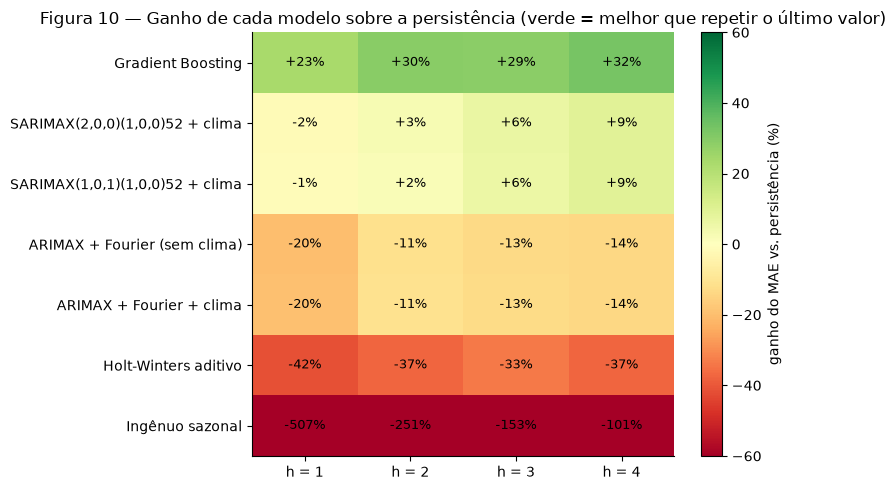

In [29]:
def metricas(g):
    e = g["previsto"] - g["observado"]
    return pd.Series({"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
                      "WAPE (%)": e.abs().sum() / g["observado"].sum() * 100, "n": len(g)})


def tabela_metricas(df, chaves):
    t = df.groupby(chaves + ["modelo"])[["previsto", "observado"]].apply(metricas).reset_index()
    ref = t[t.modelo == "Persistência"].set_index(chaves)["MAE"]
    t["Ganho vs. persistência (%)"] = (1 - t["MAE"] / t.set_index(chaves).index.map(ref)) * 100
    t["n"] = t["n"].astype(int)
    return t.round({"MAE": 1, "RMSE": 1, "WAPE (%)": 1, "Ganho vs. persistência (%)": 1})


metricas_h = tabela_metricas(previsoes, ["h"])
ordem_modelos = (metricas_h[metricas_h.h == H].sort_values("MAE")["modelo"].tolist())
tabela14 = metricas_h.pivot_table(index="modelo", columns="h", values=["WAPE (%)", "Ganho vs. persistência (%)"]).reindex(ordem_modelos)
print(f"Tabela 14 — WAPE e ganho do MAE sobre a persistência por horizonte (semanas), anos de teste {ANOS_TESTE} agregados")
display(tabela14)
print("MAE e RMSE completos:")
display(metricas_h.pivot_table(index="modelo", columns="h", values=["MAE", "RMSE"]).reindex(ordem_modelos))

ganho = tabela14["Ganho vs. persistência (%)"].drop(index=["Persistência"], errors="ignore")
fig, ax = plt.subplots(figsize=(8, 0.5 * len(ganho) + 1.5))
lim = np.nanmax(np.abs(ganho.clip(-60, 60).values))
im = ax.imshow(ganho.clip(-60, 60).values, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(H)); ax.set_xticklabels([f"h = {h}" for h in ganho.columns])
ax.set_yticks(range(len(ganho))); ax.set_yticklabels(ganho.index)
for i in range(ganho.shape[0]):
    for j in range(ganho.shape[1]):
        ax.text(j, i, f"{ganho.values[i, j]:+.0f}%", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="ganho do MAE vs. persistência (%)")
ax.set_title("Figura 10 — Ganho de cada modelo sobre a persistência (verde = melhor que repetir o último valor)")
plt.tight_layout(); plt.show()

**Análise:** Com uma semana de antecedência, nenhum modelo supera claramente a persistência: como a série tem autocorrelação muito alta (Figura 8), o valor desta semana já é uma ótima estimativa da próxima (na execução anterior, MAE de 286,5 casos para a persistência contra 290,2 do SARIMAX). A vantagem dos modelos aparece com o aumento do horizonte: o SARIMAX sazonal com clima reduziu o MAE em cerca de 9% em quatro semanas, porque o termo sazonal antecipa a subida e a descida típicas da temporada, que a persistência não enxerga. O ingênuo sazonal é o pior em todos os horizontes: repetir o ano anterior falha justamente porque a intensidade das epidemias muda muito de um ano para outro (Figura 4). <!-- CONFERIR: incluir aqui o desempenho do Holt-Winters, do Gradient Boosting e da LSTM na Tabela 14 -->

A Tabela 15 detalha o ganho sobre a persistência por ano de teste, para verificar se o resultado é consistente ou depende de um ano específico.

In [30]:
metricas_ano = tabela_metricas(previsoes, ["ano_teste", "h"])
tabela15 = (metricas_ano.pivot_table(index=["modelo", "h"], columns="ano_teste", values="Ganho vs. persistência (%)")
            .drop(index=["Persistência", "Ingênuo sazonal"], level=0, errors="ignore"))
tabela15 = tabela15.reindex([m for m in ordem_modelos if m in tabela15.index.get_level_values(0)], level=0)
print("Tabela 15 — Ganho do MAE sobre a persistência (%) por ano de teste e horizonte")
tabela15

Tabela 15 — Ganho do MAE sobre a persistência (%) por ano de teste e horizonte


ano_teste                          2023  2024  2025
modelo                          h                  
Gradient Boosting               1  17.1  27.2   4.6
                                2  19.8  33.4  12.2
                                3  30.1  31.6   2.2
                                4  23.5  36.3   5.0
SARIMAX(2,0,0)(1,0,0)52 + clima 1   4.5  -4.1   4.4
                                2   0.5   1.7  11.2
                                3  -1.3   7.1  11.5
                                4   2.1  10.0  13.7
SARIMAX(1,0,1)(1,0,0)52 + clima 1   3.3  -3.2   5.2
                                2  -0.6   0.9  11.1
                                3  -2.3   6.6  11.3
                                4   1.1   9.9  13.7
ARIMAX + Fourier (sem clima)    1  18.5 -30.1  -5.9
                                2  23.1 -19.3   7.9
                                3  28.1 -20.5  -3.8
                                4  27.5 -19.6 -16.7
ARIMAX + Fourier + clima        1  18.7 -29.9  -5.6
                                2  24.1 -19.0   6.1
                                3  28.5 -20.2  -4.1
                                4  28.0 -19.8 -17.1
Holt-Winters aditivo            1   4.3 -54.7 -20.0
                                2  12.1 -50.4   2.2
                                3  33.4 -45.2 -15.5
                                4  38.0 -48.6 -31.4

**Análise:** O ARIMAX com termos de Fourier foi o modelo mais instável entre os anos: muito melhor que a persistência em 2023 (cerca de +28% em quatro semanas) e bem pior em 2024 (cerca de −20%). A explicação está na EDA: os termos de Fourier impõem a mesma curva sazonal todo ano, e em 2024 a epidemia começou semanas antes do padrão médio e foi muito mais intensa (Tabela 6), justamente o tipo de ano em que uma sazonalidade fixa erra. O SARIMAX, cuja sazonalidade é autorregressiva (depende dos valores observados 52 semanas antes, e não de uma curva fixa), oscilou menos. As versões do ARIMAX com e sem clima tiveram desempenho praticamente igual: como o clima só pode entrar com pelo menos quatro semanas de defasagem e é ele próprio sazonal, a informação que traz já está, em grande parte, nos termos de Fourier. <!-- CONFERIR: valores da Tabela 15 e consistência do Holt-Winters, Gradient Boosting e LSTM entre os anos -->

A Tabela 16 avalia os intervalos de previsão de 80%, disponíveis para os modelos da família SARIMAX: a cobertura empírica deve ficar próxima de 80%, e a largura indica a utilidade prática da faixa.

In [31]:
com_ic = previsoes.dropna(subset=["ic_inf"]).copy()
com_ic["dentro"] = (com_ic["observado"] >= com_ic["ic_inf"]) & (com_ic["observado"] <= com_ic["ic_sup"])
com_ic["largura"] = com_ic["ic_sup"] - com_ic["ic_inf"]
tabela16 = (com_ic.groupby(["modelo", "h"]).agg(**{"Cobertura (%)": ("dentro", lambda s: s.mean() * 100),
                                                    "Largura média (casos)": ("largura", "mean")})
            .round(1).reset_index()
            .pivot_table(index="modelo", columns="h", values=["Cobertura (%)", "Largura média (casos)"]))
print(f"Tabela 16 — Cobertura e largura dos intervalos de previsão de {int((1 - ALPHA_IC) * 100)}%, anos de teste agregados")
tabela16

Tabela 16 — Cobertura e largura dos intervalos de previsão de 80%, anos de teste agregados


Cobertura (%)                   Largura média (casos)                        
h                                           1     2     3     4                     1       2       3       4
modelo                                                                                                       
ARIMAX + Fourier (sem clima)             89.7  86.3  84.0  85.7                1093.3  1432.3  1787.9  2119.0
ARIMAX + Fourier + clima                 89.7  86.3  84.7  86.4                1090.4  1428.4  1782.4  2113.7
SARIMAX(1,0,1)(1,0,0)52 + clima          92.9  87.6  85.3  82.3                1068.8  1380.3  1614.5  1805.8
SARIMAX(2,0,0)(1,0,0)52 + clima          92.3  87.6  85.3  81.6                1067.9  1361.7  1601.8  1794.4

**Análise:** As coberturas ficaram ligeiramente acima de 80% (entre 82% e 93% na execução anterior), ou seja, os intervalos são confiáveis e um pouco conservadores. Para a gestão, isso permite usar o limite superior do intervalo como cenário de planejamento. A largura cresce com o horizonte, refletindo a maior incerteza de previsões mais distantes.

A Figura 11 compara, em cada ano de teste, os casos observados com as previsões feitas quatro semanas antes pelo modelo de menor MAE nesse horizonte, com o intervalo de 80% quando disponível e os limiares provisórios de alerta.

Menor MAE em h = 4 → Gradient Boosting | modelo exibido na figura: SARIMAX(2,0,0)(1,0,0)52 + clima


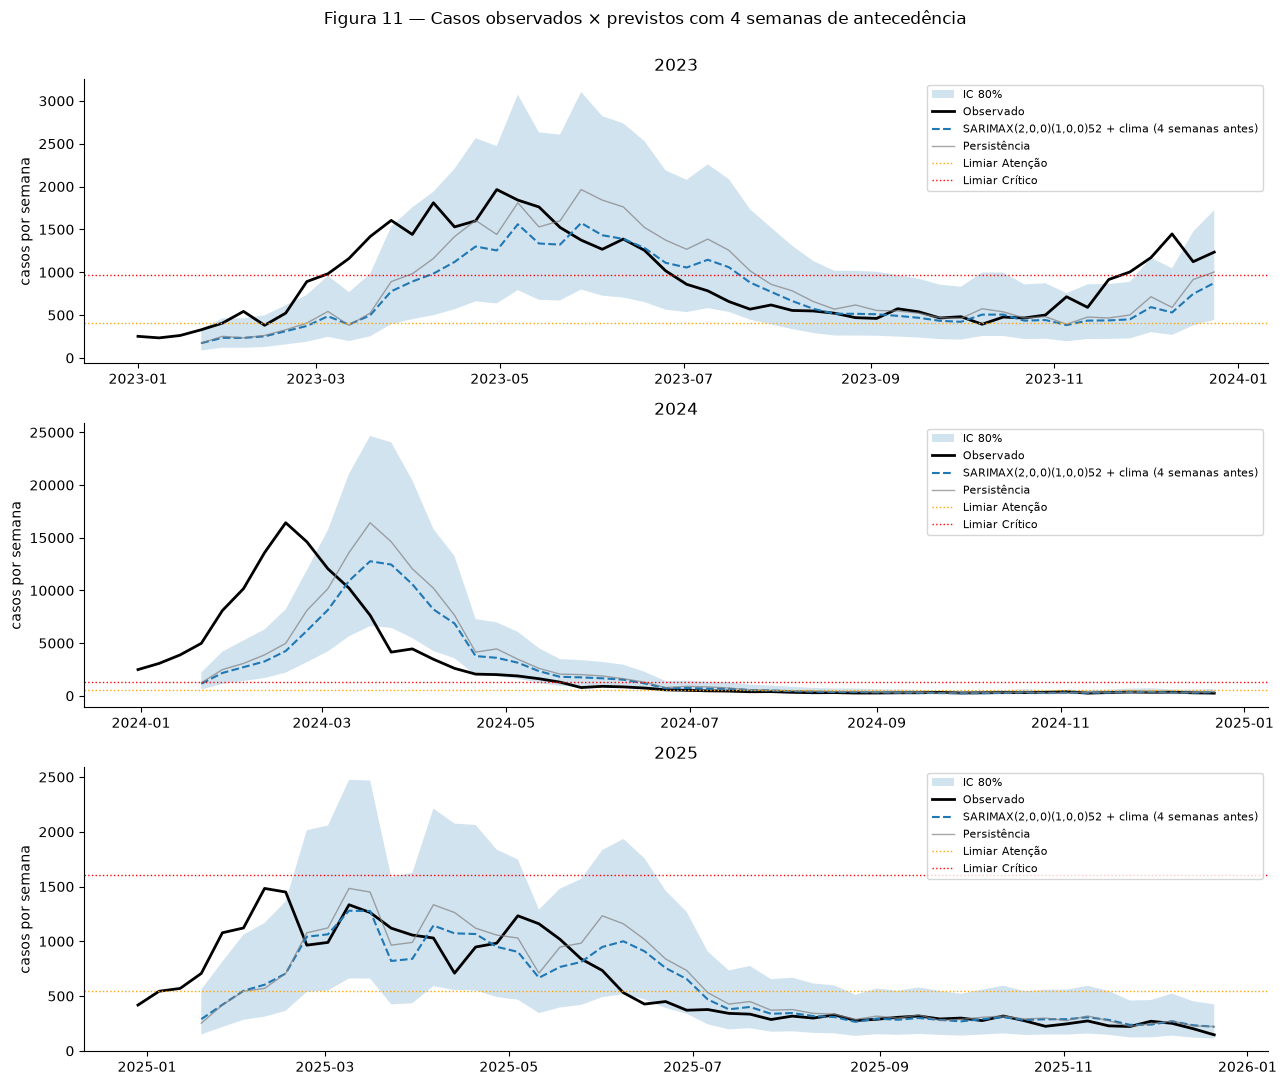

In [32]:
candidatos = [m for m in ordem_modelos if m not in ("Persistência", "Ingênuo sazonal")]
melhor_modelo = candidatos[0]
modelo_figura = melhor_modelo if previsoes.loc[previsoes.modelo == melhor_modelo, "ic_inf"].notna().any() else \
    next((m for m in candidatos if previsoes.loc[previsoes.modelo == m, "ic_inf"].notna().any()), melhor_modelo)
print("Menor MAE em h =", H, "→", melhor_modelo, "| modelo exibido na figura:", modelo_figura)

fig, axes = plt.subplots(len(ANOS_TESTE), 1, figsize=(13, 3.6 * len(ANOS_TESTE)))
for ax, ano in zip(np.atleast_1d(axes), ANOS_TESTE):
    f = folds[ano]
    obs = casos[f["teste"]]
    s = previsoes[(previsoes.ano_teste == ano) & (previsoes.modelo == modelo_figura) & (previsoes.h == H)].set_index("alvo")
    p = previsoes[(previsoes.ano_teste == ano) & (previsoes.modelo == "Persistência") & (previsoes.h == H)].set_index("alvo")
    if s["ic_inf"].notna().any():
        ax.fill_between(s.index, s["ic_inf"], s["ic_sup"], alpha=0.2, label="IC 80%")
    ax.plot(obs.index, obs, color="black", lw=2, label="Observado")
    ax.plot(s.index, s["previsto"], ls="--", label=f"{modelo_figura} ({H} semanas antes)")
    ax.plot(p.index, p["previsto"], color="grey", lw=1, alpha=0.7, label="Persistência")
    for lim, nome, cor in zip(f["limiares"], ["Atenção", "Crítico"], ["orange", "red"]):
        ax.axhline(lim, color=cor, ls=":", lw=1, label=f"Limiar {nome}")
    ax.set_title(str(ano)); ax.set_ylabel("casos por semana"); ax.legend(loc="upper right", fontsize=8)
plt.suptitle(f"Figura 11 — Casos observados × previstos com {H} semanas de antecedência", y=1.0)
plt.tight_layout(); plt.show()

A Tabela 17 compara a semana e a magnitude do pico observado com o pico previsto quatro semanas antes por cada modelo.

In [33]:
linhas = []
for ano, f in folds.items():
    obs = casos[f["teste"]]
    pico = obs.idxmax()
    linhas.append({"ano": ano, "modelo": "Observado", "semana do pico": pico.date(), "casos no pico": round(obs.max()),
                   "atraso (semanas)": 0})
    for m in ordem_modelos:
        s = previsoes[(previsoes.ano_teste == ano) & (previsoes.modelo == m) & (previsoes.h == H)].set_index("alvo")["previsto"]
        if len(s):
            linhas.append({"ano": ano, "modelo": m, "semana do pico": s.idxmax().date(), "casos no pico": round(s.max()),
                           "atraso (semanas)": int((s.idxmax() - pico).days / 7)})
tabela17 = pd.DataFrame(linhas)
print(f"Tabela 17 — Pico observado × previsto com {H} semanas de antecedência")
display(tabela17)
print("Atraso médio do pico previsto (semanas):",
      tabela17[tabela17.modelo != "Observado"].groupby("modelo")["atraso (semanas)"].mean().round(1).to_dict())

Tabela 17 — Pico observado × previsto com 4 semanas de antecedência


,ano,modelo,semana do pico,casos no pico,atraso (semanas)
0,2023,Observado,2023-04-30,1965,0
1,2023,Gradient Boosting,2023-04-23,2370,-1
2,2023,"SARIMAX(2,0,0)(1,0,0)52 + clima",2023-05-28,1575,4
3,2023,"SARIMAX(1,0,1)(1,0,0)52 + clima",2023-05-28,1571,4
4,2023,Persistência,2023-05-28,1965,4
5,2023,ARIMAX + Fourier (sem clima),2023-04-23,1846,-1
6,2023,ARIMAX + Fourier + clima,2023-04-23,1757,-1
7,2023,Holt-Winters aditivo,2023-04-23,1848,-1
8,2023,Ingênuo sazonal,2023-05-07,531,1
9,2024,Observado,2024-02-18,16423,0


Atraso médio do pico previsto (semanas): {'ARIMAX + Fourier (sem clima)': 2.7, 'ARIMAX + Fourier + clima': 2.7, 'Gradient Boosting': 3.3, 'Holt-Winters aditivo': 2.7, 'Ingênuo sazonal': 4.0, 'Persistência': 4.0, 'SARIMAX(1,0,1)(1,0,0)52 + clima': 4.0, 'SARIMAX(2,0,0)(1,0,0)52 + clima': 4.0}


**Análise:** Os modelos tendem a prever o pico com atraso (cerca de quatro semanas no SARIMAX na execução anterior) e a subestimar sua magnitude nas epidemias intensas. Isso acontece porque, com quatro semanas de antecedência, os modelos dependem principalmente dos valores já observados, e a aceleração do início de uma epidemia só aparece nos dados quando ela já está em curso. É a principal limitação para o uso operacional e motiva, na Etapa 4, a avaliação por nível de alerta, mais tolerante a erros de magnitude do que o erro semana a semana. <!-- CONFERIR: atrasos na Tabela 17 -->

Por fim, as Tabelas 18 e 19 trazem a leitura operacional. Cada semana é classificada como Normal, Atenção ou Crítico pelos quantis de 75% e 90% dos casos no treino de cada ano (limiares provisórios, que na Etapa 4 passam a ser definidos pela capacidade de leitos). A Tabela 18 mostra o acerto do nível, a sensibilidade (das semanas que atingiram Atenção ou mais, quantas foram previstas) e a precisão (dos alertas emitidos, quantos se confirmaram); a Tabela 19 mostra, para cada vez que a série cruzou o limiar de Atenção, com quantas semanas de antecedência cada modelo já previa o cruzamento.

In [34]:
def nivel(valor, limiares):
    return int(np.select([valor >= limiares[1], valor >= limiares[0]], [2, 1], default=0))   # 0 Normal, 1 Atenção, 2 Crítico


previsoes["nivel_prev"] = [nivel(v, folds[a]["limiares"]) for v, a in zip(previsoes["previsto"], previsoes["ano_teste"])]
previsoes["nivel_obs"] = [nivel(v, folds[a]["limiares"]) for v, a in zip(previsoes["observado"], previsoes["ano_teste"])]


def avaliar_alerta(g):
    alerta_prev, alerta_obs = g["nivel_prev"] >= 1, g["nivel_obs"] >= 1
    vp = (alerta_prev & alerta_obs).sum()
    return pd.Series({"Acerto do nível (%)": (g["nivel_prev"] == g["nivel_obs"]).mean() * 100,
                      "Sensibilidade (%)": vp / alerta_obs.sum() * 100 if alerta_obs.sum() else np.nan,
                      "Precisão (%)": vp / alerta_prev.sum() * 100 if alerta_prev.sum() else np.nan})


tabela18 = (previsoes.groupby(["modelo", "h"])[["nivel_prev", "nivel_obs"]].apply(avaliar_alerta).round(1).reset_index()
            .pivot_table(index="modelo", columns="h", values=["Acerto do nível (%)", "Sensibilidade (%)", "Precisão (%)"])
            .reindex(ordem_modelos))
print("Tabela 18 — Classificação de alerta (Atenção ou acima), anos de teste agregados")
display(tabela18)

linhas = []
for ano, f in folds.items():
    L = f["limiares"][0]
    obs = casos[f["treino"] | f["teste"]]
    for t in y.index[f["teste"]]:
        if obs[t] >= L and obs.shift(1)[t] < L:
            for m in ordem_modelos:
                p = previsoes[(previsoes.ano_teste == ano) & (previsoes.modelo == m) & (previsoes.alvo == t)]
                avisos = p[p["previsto"] >= L]
                linhas.append({"ano": ano, "entrada em alerta": t.date(), "modelo": m,
                               "antecedência (semanas)": int(avisos["h"].max()) if len(avisos) else 0})
entradas = pd.DataFrame(linhas)
if entradas.empty:
    print("Nenhuma entrada em alerta nos anos de teste com os limiares atuais.")
else:
    tabela19 = (entradas.groupby("modelo").agg(**{
        "Entradas em alerta": ("antecedência (semanas)", "size"),
        "Avisadas com antecedência (%)": ("antecedência (semanas)", lambda s: (s > 0).mean() * 100),
        "Antecedência média (semanas)": ("antecedência (semanas)", "mean")}).round(1)
        .sort_values(["Avisadas com antecedência (%)", "Antecedência média (semanas)"], ascending=False))
    print("Tabela 19 — Antecedência na entrada em alerta (limiar de Atenção), anos de teste agregados")
    display(tabela19)

Tabela 18 — Classificação de alerta (Atenção ou acima), anos de teste agregados


Acerto do nível (%)                   Precisão (%)                   Sensibilidade (%)                  
h                                                 1     2     3     4            1     2     3     4                 1     2     3     4
modelo                                                                                                                                  
Gradient Boosting                              95.5  88.2  80.0  79.6         96.8  94.5  93.8  93.8              97.8  93.5  83.5  85.4
SARIMAX(2,0,0)(1,0,0)52 + clima                91.7  87.6  82.7  78.9         95.8  94.6  93.3  91.1              97.8  94.6  92.3  92.1
SARIMAX(1,0,1)(1,0,0)52 + clima                90.4  86.9  82.7  78.2         95.7  94.6  93.3  91.0              95.7  94.6  92.3  91.0
Persistência                                   91.7  87.6  82.7  77.6         95.7  94.6  92.3  90.0              95.7  94.6  92.3  91.0
ARIMAX + Fourier (sem clima)                   94.2  88.2  83.3  78.2         96.8  95.6  96.4  96.2              98.9  94.6  89.0  84.3
ARIMAX + Fourier + clima                       92.9  88.2  83.3  77.6         96.8  95.6  96.4  96.2              96.8  94.6  89.0  84.3
Holt-Winters aditivo                           93.6  88.9  84.7  81.0         96.8  95.7  94.5  94.2              97.8  96.7  94.5  91.0
Ingênuo sazonal                                37.2  37.3  37.3  37.4         67.6  68.7  69.7  69.2              49.5  50.0  50.5  50.6

Tabela 19 — Antecedência na entrada em alerta (limiar de Atenção), anos de teste agregados


,Entradas em alerta,Avisadas com antecedência (%),Antecedência média (semanas)
modelo,,,
ARIMAX + Fourier (sem clima),4,100.0,2.5
Gradient Boosting,4,100.0,2.5
Holt-Winters aditivo,4,75.0,2.0
ARIMAX + Fourier + clima,4,50.0,2.0
Persistência,4,50.0,1.5
"SARIMAX(1,0,1)(1,0,0)52 + clima",4,50.0,1.5
"SARIMAX(2,0,0)(1,0,0)52 + clima",4,50.0,1.5
Ingênuo sazonal,4,25.0,0.8


**Análise:** Na classificação por nível, os modelos ficam próximos da persistência em horizontes curtos e se diferenciam em três e quatro semanas. Na antecipação da entrada em alerta, o número de eventos é pequeno (quatro cruzamentos do limiar de Atenção nos três anos, na execução anterior), por isso as porcentagens devem ser lidas com cautela: um evento a mais ou a menos muda o resultado em 25 pontos percentuais. Na execução anterior, o ARIMAX com Fourier sem clima avisou com antecedência os quatro cruzamentos, contra dois de quatro do SARIMAX e da persistência, o que sugere que a sazonalidade explícita ajuda a antecipar o início da temporada, mesmo sendo pior no erro médio. Esse contraste entre erro médio e antecipação será um critério da escolha do modelo final na Etapa 4. <!-- CONFERIR: Tabelas 18 e 19 -->

In [ ]:
# Resumo
print("Modelo de menor MAE por horizonte:")
for h in range(1, H + 1):
    t = metricas_h[metricas_h.h == h].sort_values("MAE")
    print(f"  h = {h}: {t.iloc[0]['modelo']} (MAE {t.iloc[0]['MAE']:.1f}; persistência "
          f"{t[t.modelo == 'Persistência']['MAE'].iloc[0]:.1f})")
print("\nModelo de menor MAE em h = 4, por ano de teste:")
for ano in ANOS_TESTE:
    t = metricas_ano[(metricas_ano.ano_teste == ano) & (metricas_ano.h == H)].sort_values("MAE")
    print(f"  {ano}: {t.iloc[0]['modelo']} (ganho {t.iloc[0]['Ganho vs. persistência (%)']:+.1f}% sobre a persistência)")

#Exportacao para etapa 4
os.makedirs("saidas", exist_ok=True)
previsoes.to_csv(f"saidas/previsoes_walkforward_{ALVO}.csv", index=False)
casos_doencas.assign(casos_alvo=casos).rename_axis("semana").to_csv(f"saidas/serie_semanal_{ALVO}.csv")
metricas_h.to_csv("saidas/metricas_por_horizonte.csv", index=False)
metricas_ano.to_csv("saidas/metricas_por_ano.csv", index=False)
print("\nArquivos salvos em saidas/")

Modelo de menor MAE por horizonte:
  h = 1: Gradient Boosting (MAE 220.2; persistência 286.5)
  h = 2: Gradient Boosting (MAE 350.0; persistência 496.5)
  h = 3: Gradient Boosting (MAE 489.7; persistência 688.7)
  h = 4: Gradient Boosting (MAE 582.2; persistência 861.9)

Modelo de menor MAE em h = 4, por ano de teste:
  2023: Holt-Winters aditivo (ganho +38.0% sobre a persistência)
  2024: Gradient Boosting (ganho +36.3% sobre a persistência)
  2025: SARIMAX(1,0,1)(1,0,0)52 + clima (ganho +13.7% sobre a persistência)

Arquivos salvos em saidas/


# **Discussão e Conclusão**

*Seção parcial, referente à Etapa 3, a análise crítica completa e a escolha do modelo final serão feitas na Etapa 4.*

**Principais achados até aqui**
- A análise exploratória mostrou uma série estacionária, com autocorrelação alta e persistente, sazonalidade anual clara porém de amplitude muito variável, e epidemias irregulares. Essas características explicam o comportamento dos modelos: a persistência é difícil de superar em horizontes curtos, e modelos com sazonalidade rígida erram em anos atípicos.
- O SARIMAX sazonal com clima defasado foi o modelo base mais estável, com ganho modesto sobre a persistência que cresce com o horizonte (cerca de 9% em quatro semanas) e intervalos de previsão bem calibrados.
- O clima defasado não trouxe ganho adicional relevante, porque a informação climática disponível com quatro semanas de antecedência já está, em grande parte, contida na sazonalidade.
- Modelos mais flexíveis (*Gradient Boosting* e LSTM) dispõem de poucas observações semanais para aprender relações complexas (cerca de 400 semanas no treino do primeiro ano de teste), o que limita sua vantagem sobre os modelos estatísticos nesta série. <!-- CONFERIR: confirmar com as Tabelas 14 e 15 -->

**Limitações**
- Soma de duas doenças com dinâmicas diferentes, zika fora do alvo por falta de dados após fevereiro de 2024.
- Limiares de alerta provisórios, baseados em quantis de casos, ainda não na capacidade de leitos.
- Atraso de notificação: as semanas mais recentes dependem da correção de *nowcasting* do InfoDengue.
- Parâmetros fixos dentro de cada ano de teste, retransformação `exp(ŷ) − 1` estima a mediana, e não a média, dos casos.
- Hiperparâmetros da LSTM ainda não otimizados, poucos eventos de entrada em alerta para avaliar a antecipação.

**Próximos passos (Etapa 4)**
- Refinar os modelos mais promissores, analisar resíduos e comparar estatisticamente os erros entre modelos.
- Converter a previsão de casos em leitos ocupados (SIH-SUS e CNES), calibrar os limiares de alerta e desagregar a previsão por AP.
- Apresentar os resultados à equipe técnica da SMS-Rio para validar a utilidade das previsões para a tomada de decisão e entregar uma versão replicável, conforme recomendado na disciplina: é quem usaria o dado que pode dizer quais decisões ele de fato apoia.

# **Apresentação**

O link do vídeo de apresentação será incluído na entrega final (Etapa 4).

# **Referências**

BOX, G. E. P.; COX, D. R. An analysis of transformations. **Journal of the Royal Statistical Society, Series B, Statistical Methodology**, v. 26, n. 2, p. 211-252, 1964.

BOX, G. E. P.; JENKINS, G. M. **Time Series Analysis: Forecasting and Control**. San Francisco: Holden-Day, 1970.

BRASIL. Ministério da Saúde. Departamento de Informática do SUS (DATASUS). **Doenças e Agravos de Notificação – 2007 em diante (SINAN)**. Brasília, DF: Ministério da Saúde, 2026. Disponível em: https://datasus.saude.gov.br/.

CLEVELAND, R. B. et al. STL: A seasonal-trend decomposition procedure based on Loess. **Journal of Official Statistics**, v. 6, n. 1, p. 3-73, 1990.

CODEÇO, C. T. et al. Infodengue: a nowcasting system for the surveillance of arboviruses in Brazil. **Revue d'Épidémiologie et de Santé Publique**, v. 66, supl. 5, p. S386, 2018.

DICKEY, D. A.; FULLER, W. A. Distribution of the estimators for autoregressive time series with a unit root. **Journal of the American Statistical Association**, v. 74, n. 366, p. 427-431, 1979.

FRIEDMAN, J. H. Greedy function approximation: a gradient boosting machine. **The Annals of Statistics**, v. 29, n. 5, p. 1189-1232, 2001.

FUNDAÇÃO OSWALDO CRUZ. **Observatório Clima e Saúde: Mudanças climáticas e crescimento da dengue no Brasil**. Rio de Janeiro: Fiocruz, 2026. Disponível em: https://climaesaude.icict.fiocruz.br/.

GUERRERO, V. M. Time-series analysis supported by power transformations. **Journal of Forecasting**, v. 12, n. 1, p. 37-48, 1993.

HOCHREITER, S.; SCHMIDHUBER, J. Long Short-Term Memory. **Neural Computation**, v. 9, n. 8, p. 1735-1780, 1997.

HYNDMAN, R. J.; ATHANASOPOULOS, G. **Forecasting: principles and practice**. 3. ed. Melbourne: OTexts, 2021. Disponível em: https://otexts.com/fpp3/.

INFODENGUE. **Serviços e Documentação da API**. Rio de Janeiro: Fundação Oswaldo Cruz / Fundação Getulio Vargas, 2026. Disponível em: https://info.dengue.mat.br/.

KWIATKOWSKI, D. et al. Testing the null hypothesis of stationarity against the alternative of a unit root. **Journal of Econometrics**, v. 54, n. 1-3, p. 159-178, 1992.

MARTINEZ, E. Z.; SILVA, E. A. S. da. Predicting the number of cases of dengue infection in Ribeirão Preto, São Paulo State, Brazil, using a SARIMA model. **Cadernos de Saúde Pública**, v. 27, n. 9, p. 1809-1818, 2011.

PASZKE, A. et al. PyTorch: an imperative style, high-performance deep learning library. In: **Advances in Neural Information Processing Systems 32**. Vancouver: Curran Associates, 2019. p. 8024-8035.

PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. **Journal of Machine Learning Research**, v. 12, p. 2825-2830, 2011.

SAHD, C. S.; LIZZI, E. A. da S.; BRESSAN, G. M.; VILAS-BOAS, L. A. Forecasting Using SARIMAX Model and LSTM Approach for Arboviruses Using Exogenous Climatic Variables in Predicting Dengue Incidence. In: **Bioinformatics and Computational Biology (X-Meeting 2025)**. Cham: Springer, 2026. p. 214-226.

SEABOLD, S.; PERKTOLD, J. Statsmodels: econometric and statistical modeling with Python. In: PYTHON IN SCIENCE CONFERENCE, 9., 2010, Austin. **Proceedings** [...]. Austin: SciPy, 2010. p. 92-96.

TAYLOR, S. J.; LETHAM, B. Forecasting at scale. **The American Statistician**, v. 72, n. 1, p. 37-45, 2018.

WANG, X.; SMITH, K.; HYNDMAN, R. Characteristic-based clustering for time series data. **Data Mining and Knowledge Discovery**, v. 13, n. 3, p. 335-364, 2006.

WINTERS, P. R. Forecasting sales by exponentially weighted moving averages. **Management Science**, v. 6, n. 3, p. 324-342, 1960.

ZIPPENFENIG, P. **Open-Meteo.com Weather API**. Zenodo, 2023. Disponível em: https://open-meteo.com/. DOI: 10.5281/zenodo.7970649.